# Comparative Analysis of the HBB (Beta-Globin) Gene Across Species 🧬

**Project 02 — Bioinformatics and Genetics**

**Research Question:**
How conserved is the beta-globin gene across different species, and what genetic variations can we identify?


## Project Overview

Comparative genomics is the study of similarities and differences between the genetic sequences of different organisms.

In this project, we investigate the **HBB (Beta-Globin) gene**, which encodes a component of hemoglobin, the protein responsible for oxygen transport in red blood cells.

Using Python and bioinformatics tools, we will retrieve real biological sequences from different species, compare their genetic composition, identify conserved regions, and investigate sequence variations.

The project will also explore genetic similarity and evolutionary relationships through multiple sequence alignment and phylogenetic analysis.

By combining biological knowledge with computational methods, this project aims to demonstrate how bioinformatics can help us understand genetic conservation and variation across species.



## Research Objectives

The main objectives of this project are to:

1. Retrieve HBB gene sequences from different species using biological databases.
2. Process and validate the retrieved DNA sequences.
3. Perform multiple sequence alignment.
4. Identify conserved and variable nucleotide positions.
5. Detect and classify genetic variations.
6. Calculate sequence similarity between species.
7. Construct a phylogenetic tree.
8. Visualize and interpret the comparative analysis results.



## Dataset Selection

This project uses HBB (beta-globin) gene records retrieved from the NCBI database.

The initial dataset includes four mammalian species:

1. Homo sapiens (Human)
2. Pan troglodytes (Chimpanzee)
3. Bos taurus (Cattle)
4. Ovis aries (Sheep)

The sequences will be selected from annotated protein-coding gene records. Their accession numbers, sequence types, and database annotations will be documented to ensure reproducibility.

The dataset may be expanded after verifying additional orthologous sequences.



## Data Sources and Selection Criteria

Biological sequence data for this project will be obtained from the National Center for Biotechnology Information (NCBI).

The study focuses on the HBB gene, which encodes the beta-globin subunit of hemoglobin.

Species will be selected based on the availability of reliable gene annotations and comparable orthologous coding sequences.

To ensure consistency and reproducibility:

- Only verified gene records will be considered.
- Coding DNA sequences (CDS) will be used for nucleotide-level comparisons.
- Gene identifiers and sequence accession numbers will be recorded.
- Sequence annotations and biological relevance will be examined before analysis.
- Potential differences between orthologous and paralogous genes will be considered.

The final dataset will be established after sequence retrieval and quality assessment.



## NCBI Data Retrieval

The National Center for Biotechnology Information (NCBI) provides access to biological databases containing nucleotide sequences, protein sequences, gene annotations, and scientific literature.

In this project, NCBI's Entrez programming utilities will be used to retrieve biological records programmatically.

Biopython's Entrez module will help us communicate with NCBI, while SeqIO will allow us to parse and inspect the retrieved sequence records.

Each retrieved record will be examined for:

- Organism name
- Gene identity
- Accession number and version
- Sequence type
- Coding sequence (CDS) annotation
- Sequence length

The retrieved records will be evaluated before being included in the final comparative dataset.


In [260]:
# Install Biopython
!pip install -q biopython

# Import required modules
from Bio import Entrez, SeqIO
from Bio.Seq import Seq

# Configure NCBI Entrez
Entrez.email = "your_email@example.com"

print("Biopython version:", __import__("Bio").__version__)
print("NCBI Entrez is configured successfully.")


Biopython version: 1.88
NCBI Entrez is configured successfully.


In [261]:
# Search NCBI for human HBB mRNA records
handle = Entrez.esearch(
    db="nuccore",
    term="Homo sapiens[Organism] AND HBB[Gene] AND biomol_mrna[PROP]",
    retmax=10
)

search_results = Entrez.read(handle)
handle.close()

# Display the number of records found
id_list = search_results["IdList"]

print("Number of records found:", len(id_list))
print("NCBI record IDs:", id_list)

Number of records found: 10
NCBI record IDs: ['1401724401', '2787674884', '6003531', '13937928', '183821', '23268448', '13549111', '6003533', '4378803', '49456780']


In [262]:
# Retrieve summaries for the NCBI records
handle = Entrez.esummary(db="nuccore", id=",".join(id_list))
summaries = Entrez.read(handle)
handle.close()

# Display important information about each record
for record in summaries:
    print("Accession:", record["AccessionVersion"])
    print("Description:", record["Title"])
    print("-" * 70)

Accession: NM_000518.5
Description: Homo sapiens hemoglobin subunit beta (HBB), mRNA
----------------------------------------------------------------------
Accession: OR521158.1
Description: Homo sapiens Hb Monza protein (HBB) mRNA, complete cds
----------------------------------------------------------------------
Accession: AF181832.1
Description: Homo sapiens hemoglobin beta subunit variant (HBB) mRNA, partial cds
----------------------------------------------------------------------
Accession: BC007075.1
Description: Homo sapiens hemoglobin, beta, mRNA (cDNA clone MGC:14540 IMAGE:4292125), complete cds
----------------------------------------------------------------------
Accession: M11428.1
Description: Human beta-globin mRNA, 3' end
----------------------------------------------------------------------
Accession: AY136510.1
Description: Homo sapiens hemoglobin beta chain variant Hb S-Wake (HBB) mRNA, complete cds
-------------------------------------------------------------------

In [263]:
# Retrieve the human HBB reference record
handle = Entrez.efetch(
    db="nuccore",
    id="NM_000518.5",
    rettype="gb",
    retmode="text"
)

human_record = SeqIO.read(handle, "genbank")
handle.close()

# Display general record information
print("Accession:", human_record.id)
print("Description:", human_record.description)
print("Organism:", human_record.annotations.get("organism"))
print("Sequence length:", len(human_record.seq))

# Inspect the coding sequence (CDS)
for feature in human_record.features:
    if feature.type == "CDS":
        print("\nCDS location:", feature.location)
        print("Gene:", feature.qualifiers.get("gene"))
        print("Product:", feature.qualifiers.get("product"))
        print("Protein ID:", feature.qualifiers.get("protein_id"))
        print("Translation:", feature.qualifiers.get("translation"))

Accession: NM_000518.5
Description: Homo sapiens hemoglobin subunit beta (HBB), mRNA
Organism: Homo sapiens
Sequence length: 628

CDS location: [50:494](+)
Gene: ['HBB']
Product: ['hemoglobin subunit beta']
Protein ID: ['NP_000509.1']
Translation: ['MVHLTPEEKSAVTALWGKVNVDEVGGEALGRLLVVYPWTQRFFESFGDLSTPDAVMGNPKVKAHGKKVLGAFSDGLAHLDNLKGTFATLSELHCDKLHVDPENFRLLGNVLVCVLAHHFGKEFTPPVQAAYQKVVAGVANALAHKYH']


In [264]:
# Extract the HBB coding sequence (CDS)
human_cds_feature = next(
    feature for feature in human_record.features
    if feature.type == "CDS" and "HBB" in feature.qualifiers.get("gene", [])
)

human_cds = human_cds_feature.extract(human_record.seq)

# Store the sequence and its metadata
human_data = {
    "species": "Homo sapiens",
    "gene": "HBB",
    "accession": human_record.id,
    "sequence": human_cds
}

# Display a clean summary
print("HUMAN HBB — CDS SUMMARY")
print("-" * 35)
print(f"Species:       {human_data['species']}")
print(f"Gene:          {human_data['gene']}")
print(f"Accession:     {human_data['accession']}")
print(f"CDS length:    {len(human_cds)} bp")
print(f"Start codon:   {human_cds[:3]}")
print(f"Stop codon:    {human_cds[-3:]}")
print(f"Sequence:      {human_cds}")

HUMAN HBB — CDS SUMMARY
-----------------------------------
Species:       Homo sapiens
Gene:          HBB
Accession:     NM_000518.5
CDS length:    444 bp
Start codon:   ATG
Stop codon:    TAA
Sequence:      ATGGTGCATCTGACTCCTGAGGAGAAGTCTGCCGTTACTGCCCTGTGGGGCAAGGTGAACGTGGATGAAGTTGGTGGTGAGGCCCTGGGCAGGCTGCTGGTGGTCTACCCTTGGACCCAGAGGTTCTTTGAGTCCTTTGGGGATCTGTCCACTCCTGATGCTGTTATGGGCAACCCTAAGGTGAAGGCTCATGGCAAGAAAGTGCTCGGTGCCTTTAGTGATGGCCTGGCTCACCTGGACAACCTCAAGGGCACCTTTGCCACACTGAGTGAGCTGCACTGTGACAAGCTGCACGTGGATCCTGAGAACTTCAGGCTCCTGGGCAACGTGCTGGTCTGTGTGCTGGCCCATCACTTTGGCAAAGAATTCACCCCACCAGTGCAGGCTGCCTATCAGAAAGTGGTGGCTGGTGTGGCTAATGCCCTGGCCCACAAGTATCACTAA


In [265]:
# Validate the human HBB coding sequence
valid_bases = set("ATCG")
stop_codons = {"TAA", "TAG", "TGA"}

checks = {
    "Valid DNA bases": set(str(human_cds)).issubset(valid_bases),
    "Correct start codon": str(human_cds[:3]) == "ATG",
    "Valid stop codon": str(human_cds[-3:]) in stop_codons,
    "Length divisible by 3": len(human_cds) % 3 == 0
}

print("HBB SEQUENCE QUALITY CHECK")
print("-" * 35)

for check, passed in checks.items():
    print(f"{check:<25} {'PASS' if passed else 'FAIL'}")

print("-" * 35)
print(f"Overall result: {'PASSED' if all(checks.values()) else 'FAILED'}")

HBB SEQUENCE QUALITY CHECK
-----------------------------------
Valid DNA bases           PASS
Correct start codon       PASS
Valid stop codon          PASS
Length divisible by 3     PASS
-----------------------------------
Overall result: PASSED


## Comparative Sequence Retrieval

After validating the human HBB coding sequence, we will retrieve corresponding HBB coding sequences from other species.

Each sequence will undergo the same annotation checks and quality-control procedures before inclusion in the comparative dataset.

This ensures that our analysis uses comparable biological sequences and reduces the risk of including unrelated genes or incomplete records.

In [266]:
# Search NCBI for chimpanzee HBB mRNA records
handle = Entrez.esearch(
    db="nuccore",
    term="Pan troglodytes[Organism] AND HBB[Gene] AND biomol_mrna[PROP]",
    retmax=10
)

chimp_search = Entrez.read(handle)
handle.close()

chimp_ids = chimp_search["IdList"]

# Display search results
print("CHIMPANZEE HBB — SEARCH RESULTS")
print("-" * 40)
print(f"Records found: {len(chimp_ids)}")
print(f"NCBI record IDs: {chimp_ids}")

CHIMPANZEE HBB — SEARCH RESULTS
----------------------------------------
Records found: 1
NCBI record IDs: ['2468480781']


In [267]:
# Retrieve the chimpanzee record summary
handle = Entrez.esummary(db="nuccore", id=",".join(chimp_ids))
chimp_summaries = Entrez.read(handle)
handle.close()

# Display record information
print("CHIMPANZEE HBB — RECORD DETAILS")
print("-" * 45)

for record in chimp_summaries:
    print(f"Accession:   {record['AccessionVersion']}")
    print(f"Description: {record['Title']}")

CHIMPANZEE HBB — RECORD DETAILS
---------------------------------------------
Accession:   XM_508242.5
Description: PREDICTED: Pan troglodytes hemoglobin subunit beta (HBB), mRNA


In [268]:
# Retrieve the chimpanzee HBB GenBank record
handle = Entrez.efetch(
    db="nuccore",
    id="XM_508242.5",
    rettype="gb",
    retmode="text"
)

chimp_record = SeqIO.read(handle, "genbank")
handle.close()

# Display record information
print("CHIMPANZEE HBB — RECORD SUMMARY")
print("-" * 40)
print(f"Accession: {chimp_record.id}")
print(f"Organism:  {chimp_record.annotations.get('organism')}")
print(f"Length:    {len(chimp_record.seq)} bp")

# Inspect the annotated HBB coding region
for feature in chimp_record.features:
    if feature.type == "CDS" and "HBB" in feature.qualifiers.get("gene", []):
        print("\nCDS annotation found")
        print(f"Location:  {feature.location}")
        print(f"Gene:      {feature.qualifiers.get('gene')}")
        print(f"Product:   {feature.qualifiers.get('product')}")
        print(f"Protein:   {feature.qualifiers.get('protein_id')}")
        print(f"Translation: {feature.qualifiers.get('translation')}")

CHIMPANZEE HBB — RECORD SUMMARY
----------------------------------------
Accession: XM_508242.5
Organism:  Pan troglodytes
Length:    639 bp

CDS annotation found
Location:  [61:505](+)
Gene:      ['HBB']
Product:   ['hemoglobin subunit beta']
Protein:   ['XP_508242.1']
Translation: ['MVHLTPEEKSAVTALWGKVNVDEVGGEALGRLLVVYPWTQRFFESFGDLSTPDAVMGNPKVKAHGKKVLGAFSDGLAHLDNLKGTFATLSELHCDKLHVDPENFRLLGNVLVCVLAHHFGKEFTPPVQAAYQKVVAGVANALAHKYH']


In [269]:
# Extract the chimpanzee HBB coding sequence
chimp_cds_feature = next(
    feature for feature in chimp_record.features
    if feature.type == "CDS"
    and "HBB" in feature.qualifiers.get("gene", [])
)

chimp_cds = chimp_cds_feature.extract(chimp_record.seq)

# Store the sequence and its metadata
chimp_data = {
    "species": "Pan troglodytes",
    "gene": "HBB",
    "accession": chimp_record.id,
    "sequence": chimp_cds
}

# Display a clean summary
print("CHIMPANZEE HBB — CDS SUMMARY")
print("-" * 40)
print(f"Species:       {chimp_data['species']}")
print(f"Gene:          {chimp_data['gene']}")
print(f"Accession:     {chimp_data['accession']}")
print(f"CDS length:    {len(chimp_cds)} bp")
print(f"Start codon:   {chimp_cds[:3]}")
print(f"Stop codon:    {chimp_cds[-3:]}")

CHIMPANZEE HBB — CDS SUMMARY
----------------------------------------
Species:       Pan troglodytes
Gene:          HBB
Accession:     XM_508242.5
CDS length:    444 bp
Start codon:   ATG
Stop codon:    TAA


In [270]:
# Validate the chimpanzee HBB coding sequence
chimp_sequence = str(chimp_cds)

valid_bases = set("ATCG")
stop_codons = {"TAA", "TAG", "TGA"}

checks = {
    "Valid DNA bases": set(chimp_sequence).issubset(valid_bases),
    "Correct start codon": chimp_sequence[:3] == "ATG",
    "Valid stop codon": chimp_sequence[-3:] in stop_codons,
    "Length divisible by 3": len(chimp_sequence) % 3 == 0
}

print("CHIMPANZEE HBB — QUALITY CHECK")
print("-" * 40)

for check, passed in checks.items():
    status = "PASS" if passed else "FAIL"
    print(f"{check:<25} {status}")

print("-" * 40)
print(f"Overall result: {'PASSED' if all(checks.values()) else 'FAILED'}")

CHIMPANZEE HBB — QUALITY CHECK
----------------------------------------
Valid DNA bases           PASS
Correct start codon       PASS
Valid stop codon          PASS
Length divisible by 3     PASS
----------------------------------------
Overall result: PASSED


In [271]:
# Compare human and chimpanzee HBB coding sequences
human_sequence = str(human_cds)
chimp_sequence = str(chimp_cds)

# Check that both sequences have equal lengths
if len(human_sequence) != len(chimp_sequence):
    raise ValueError("Sequence lengths differ. Alignment is required first.")

# Identify matching and differing positions
matching_positions = []
different_positions = []

for position, (human_base, chimp_base) in enumerate(
    zip(human_sequence, chimp_sequence), start=1
):
    if human_base == chimp_base:
        matching_positions.append(position)
    else:
        different_positions.append({
            "position": position,
            "human": human_base,
            "chimpanzee": chimp_base
        })

# Calculate preliminary sequence identity
identity = len(matching_positions) / len(human_sequence) * 100

# Display comparison results
print("HUMAN vs CHIMPANZEE — HBB COMPARISON")
print("-" * 45)
print(f"Sequence length:       {len(human_sequence)} bp")
print(f"Matching positions:    {len(matching_positions)}")
print(f"Different positions:   {len(different_positions)}")
print(f"Sequence identity:     {identity:.2f}%")

print("\nDIFFERING POSITIONS")
print("-" * 45)

if different_positions:
    for difference in different_positions:
        print(
            f"Position {difference['position']}: "
            f"Human = {difference['human']} | "
            f"Chimpanzee = {difference['chimpanzee']}"
        )
else:
    print("No differences detected.")

HUMAN vs CHIMPANZEE — HBB COMPARISON
---------------------------------------------
Sequence length:       444 bp
Matching positions:    443
Different positions:   1
Sequence identity:     99.77%

DIFFERING POSITIONS
---------------------------------------------
Position 9: Human = T | Chimpanzee = C


In [272]:
# Examine the nucleotide difference at position 9
position = 9

# Extract the codon containing the difference
codon_start = ((position - 1) // 3) * 3

human_codon = Seq(human_sequence[codon_start:codon_start + 3])
chimp_codon = Seq(chimp_sequence[codon_start:codon_start + 3])

# Translate both codons
human_amino_acid = human_codon.translate()
chimp_amino_acid = chimp_codon.translate()

print("SYNONYMOUS SUBSTITUTION ANALYSIS")
print("-" * 40)
print(f"CDS position:       {position}")
print(f"Human codon:        {human_codon}")
print(f"Chimpanzee codon:   {chimp_codon}")
print(f"Human amino acid:   {human_amino_acid}")
print(f"Chimpanzee amino acid: {chimp_amino_acid}")
print("-" * 40)
print(
    "Result:",
    "Synonymous substitution"
    if human_amino_acid == chimp_amino_acid
    else "Non-synonymous substitution"
)

SYNONYMOUS SUBSTITUTION ANALYSIS
----------------------------------------
CDS position:       9
Human codon:        CAT
Chimpanzee codon:   CAC
Human amino acid:   H
Chimpanzee amino acid: H
----------------------------------------
Result: Synonymous substitution


In [273]:
# Translate both HBB coding sequences
human_protein = human_cds.translate()
chimp_protein = chimp_cds.translate()

# Compare the protein sequences
protein_matches = sum(
    a == b for a, b in zip(human_protein, chimp_protein)
)

protein_differences = len(human_protein) - protein_matches

protein_identity = (
    protein_matches / len(human_protein)
) * 100

# Display protein comparison
print("HBB PROTEIN COMPARISON")
print("-" * 40)
print(f"Human protein length:      {len(human_protein)} aa")
print(f"Chimpanzee protein length: {len(chimp_protein)} aa")
print(f"Matching amino acids:      {protein_matches}")
print(f"Different amino acids:     {protein_differences}")
print(f"Protein identity:          {protein_identity:.2f}%")
print("-" * 40)
print(
    "Protein sequences:",
    "IDENTICAL" if protein_differences == 0 else "DIFFERENT"
)

HBB PROTEIN COMPARISON
----------------------------------------
Human protein length:      148 aa
Chimpanzee protein length: 148 aa
Matching amino acids:      148
Different amino acids:     0
Protein identity:          100.00%
----------------------------------------
Protein sequences: IDENTICAL


In [274]:
# Store the human–chimpanzee comparison results
comparison_summary = {
    "Human": {
        "CDS length": len(human_sequence),
        "Protein length": len(human_protein)
    },
    "Chimpanzee": {
        "CDS length": len(chimp_sequence),
        "Protein length": len(chimp_protein)
    }
}

print("COMPARATIVE DATASET SUMMARY")
print("=" * 45)

for species, data in comparison_summary.items():
    print(f"\n{species}")
    for metric, value in data.items():
        print(f"  {metric:<18}: {value}")

print("\nPAIRWISE COMPARISON")
print("-" * 45)
print(f"DNA identity:       {identity:.2f}%")
print(f"Protein identity:   {protein_identity:.2f}%")
print(f"DNA differences:    {len(different_positions)}")
print(f"Protein differences: {protein_differences}")

COMPARATIVE DATASET SUMMARY

Human
  CDS length        : 444
  Protein length    : 148

Chimpanzee
  CDS length        : 444
  Protein length    : 148

PAIRWISE COMPARISON
---------------------------------------------
DNA identity:       99.77%
Protein identity:   100.00%
DNA differences:    1
Protein differences: 0


In [275]:
# Search NCBI for cattle HBB mRNA records
handle = Entrez.esearch(
    db="nuccore",
    term="Bos taurus[Organism] AND HBB[Gene] AND biomol_mrna[PROP]",
    retmax=10
)

cattle_search = Entrez.read(handle)
handle.close()

cattle_ids = cattle_search["IdList"]

# Display search results
print("CATTLE HBB — SEARCH RESULTS")
print("-" * 40)
print(f"Records found: {len(cattle_ids)}")
print(f"NCBI record IDs: {cattle_ids}")

CATTLE HBB — SEARCH RESULTS
----------------------------------------
Records found: 1
NCBI record IDs: ['160358323']


In [276]:
# Retrieve the cattle HBB GenBank record
handle = Entrez.efetch(
    db="nuccore",
    id="160358323",
    rettype="gb",
    retmode="text"
)

cattle_record = SeqIO.read(handle, "genbank")
handle.close()

# Display record information
print("CATTLE HBB — RECORD SUMMARY")
print("-" * 40)
print(f"Accession: {cattle_record.id}")
print(f"Organism:  {cattle_record.annotations.get('organism')}")
print(f"Length:    {len(cattle_record.seq)} bp")

# Inspect the HBB coding region
cattle_cds_features = [
    feature for feature in cattle_record.features
    if feature.type == "CDS"
    and "HBB" in feature.qualifiers.get("gene", [])
]

if cattle_cds_features:
    for feature in cattle_cds_features:
        print("\nCDS annotation found")
        print(f"Location:   {feature.location}")
        print(f"Gene:       {feature.qualifiers.get('gene')}")
        print(f"Product:    {feature.qualifiers.get('product')}")
        print(f"Protein ID: {feature.qualifiers.get('protein_id')}")
        print(f"Translation: {feature.qualifiers.get('translation')}")
else:
    print("\nNo HBB CDS annotation found.")

CATTLE HBB — RECORD SUMMARY
----------------------------------------
Accession: NM_173917.2
Organism:  Bos taurus
Length:    633 bp

CDS annotation found
Location:   [52:490](+)
Gene:       ['HBB']
Product:    ['hemoglobin subunit beta']
Protein ID: ['NP_776342.1']
Translation: ['MLTAEEKAAVTAFWGKVKVDEVGGEALGRLLVVYPWTQRFFESFGDLSTADAVMNNPKVKAHGKKVLDSFSNGMKHLDDLKGTFAALSELHCDKLHVDPENFKLLGNVLVVVLARNFGKEFTPVLQADFQKVVAGVANALAHRYH']


In [277]:
# Extract the cattle HBB coding sequence
cattle_cds_feature = cattle_cds_features[0]
cattle_cds = cattle_cds_feature.extract(cattle_record.seq)

# Store cattle data
cattle_data = {
    "species": "Bos taurus",
    "gene": "HBB",
    "accession": cattle_record.id,
    "sequence": cattle_cds
}

# Display a clean summary
print("CATTLE HBB — CDS SUMMARY")
print("-" * 35)
print(f"Species:      {cattle_data['species']}")
print(f"Accession:    {cattle_data['accession']}")
print(f"CDS length:   {len(cattle_cds)} bp")
print(f"Start codon:  {cattle_cds[:3]}")
print(f"Stop codon:   {cattle_cds[-3:]}")
print(f"Protein size: {len(cattle_cds.translate())} amino acids")

CATTLE HBB — CDS SUMMARY
-----------------------------------
Species:      Bos taurus
Accession:    NM_173917.2
CDS length:   438 bp
Start codon:  ATG
Stop codon:   TAA
Protein size: 146 amino acids


In [278]:
# Validate the cattle HBB coding sequence
cattle_sequence = str(cattle_cds)

cattle_checks = {
    "Valid DNA bases": all(base in "ATGC" for base in cattle_sequence),
    "Correct start codon": cattle_sequence.startswith("ATG"),
    "Valid stop codon": cattle_sequence[-3:] in ["TAA", "TAG", "TGA"],
    "Length divisible by 3": len(cattle_sequence) % 3 == 0
}

print("CATTLE HBB — QUALITY CONTROL")
print("-" * 35)

for check, passed in cattle_checks.items():
    print(f"{check}: {'PASS' if passed else 'FAIL'}")

print("-" * 35)
print("Overall result:", "PASSED" if all(cattle_checks.values()) else "FAILED")

CATTLE HBB — QUALITY CONTROL
-----------------------------------
Valid DNA bases: PASS
Correct start codon: PASS
Valid stop codon: PASS
Length divisible by 3: PASS
-----------------------------------
Overall result: PASSED


In [279]:
# Search NCBI for sheep HBB mRNA
handle = Entrez.esearch(
    db="nuccore",
    term="Ovis aries[Organism] AND HBB[Gene] AND biomol_mrna[PROP]",
    retmax=10
)

sheep_search = Entrez.read(handle)
handle.close()

sheep_ids = sheep_search["IdList"]

print("SHEEP HBB — NCBI SEARCH")
print("-" * 35)
print("Records found:", len(sheep_ids))
print("NCBI IDs:", sheep_ids)

SHEEP HBB — NCBI SEARCH
-----------------------------------
Records found: 1
NCBI IDs: ['164448673']


In [280]:
# Retrieve the sheep HBB GenBank record
handle = Entrez.efetch(
    db="nuccore",
    id=sheep_ids[0],
    rettype="gb",
    retmode="text"
)

sheep_record = SeqIO.read(handle, "genbank")
handle.close()

# Display record information
print("SHEEP HBB — RECORD SUMMARY")
print("-" * 35)
print(f"Accession: {sheep_record.id}")
print(f"Organism:  {sheep_record.annotations.get('organism')}")
print(f"Length:    {len(sheep_record.seq)} bp")

# Inspect HBB coding region
sheep_cds_features = [
    feature for feature in sheep_record.features
    if feature.type == "CDS"
    and "HBB" in feature.qualifiers.get("gene", [])
]

for feature in sheep_cds_features:
    print("\nCDS annotation found")
    print(f"Location:    {feature.location}")
    print(f"Gene:        {feature.qualifiers.get('gene')}")
    print(f"Product:     {feature.qualifiers.get('product')}")
    print(f"Protein ID:  {feature.qualifiers.get('protein_id')}")
    print(f"Translation: {feature.qualifiers.get('translation')}")

SHEEP HBB — RECORD SUMMARY
-----------------------------------
Accession: NM_001097648.1
Organism:  Ovis aries
Length:    438 bp

CDS annotation found
Location:    [0:438](+)
Gene:        ['HBB']
Product:     ['hemoglobin subunit beta']
Protein ID:  ['NP_001091117.1']
Translation: ['MLTAEEKAAVTGFWGKVKVDEVGAEALGRLLVVYPWTQRFFEHFGDLSSADAVMNNAKVKAHGKKVLDSFSNGVQHLDDLKGTFAQLSELHCDKLHVDPENFRLLGNVLVVVLARHHGSEFTPVLQAEFQKVVAGVANALAHRYH']


In [281]:
# Extract the sheep HBB coding sequence
sheep_cds_feature = sheep_cds_features[0]
sheep_cds = sheep_cds_feature.extract(sheep_record.seq)

# Store sheep data
sheep_data = {
    "species": "Ovis aries",
    "gene": "HBB",
    "accession": sheep_record.id,
    "sequence": sheep_cds
}

# Display a clean summary
print("SHEEP HBB — CDS SUMMARY")
print("-" * 35)
print(f"Species:      {sheep_data['species']}")
print(f"Accession:    {sheep_data['accession']}")
print(f"CDS length:   {len(sheep_cds)} bp")
print(f"Start codon:  {sheep_cds[:3]}")
print(f"Stop codon:   {sheep_cds[-3:]}")
print(f"Protein size: {len(sheep_cds.translate())} amino acids")

SHEEP HBB — CDS SUMMARY
-----------------------------------
Species:      Ovis aries
Accession:    NM_001097648.1
CDS length:   438 bp
Start codon:  ATG
Stop codon:   TAA
Protein size: 146 amino acids


In [282]:
# Validate the sheep HBB coding sequence
sheep_sequence = str(sheep_cds)

sheep_checks = {
    "Valid DNA bases": all(base in "ATGC" for base in sheep_sequence),
    "Correct start codon": sheep_sequence.startswith("ATG"),
    "Valid stop codon": sheep_sequence[-3:] in ["TAA", "TAG", "TGA"],
    "Length divisible by 3": len(sheep_sequence) % 3 == 0
}

print("SHEEP HBB — QUALITY CONTROL")
print("-" * 35)

for check, passed in sheep_checks.items():
    print(f"{check}: {'PASS' if passed else 'FAIL'}")

print("-" * 35)
print("Overall result:", "PASSED" if all(sheep_checks.values()) else "FAILED")

SHEEP HBB — QUALITY CONTROL
-----------------------------------
Valid DNA bases: PASS
Correct start codon: PASS
Valid stop codon: PASS
Length divisible by 3: PASS
-----------------------------------
Overall result: PASSED


In [283]:
# Combine all HBB sequences into one dataset
hbb_dataset = {
    "Human": human_data,
    "Chimpanzee": chimp_data,
    "Cattle": cattle_data,
    "Sheep": sheep_data
}

# Display dataset overview
print("HBB COMPARATIVE DATASET")
print("=" * 45)

for species, data in hbb_dataset.items():
    print(f"{species:12} | {data['accession']:15} | {len(data['sequence'])} bp")

print("=" * 45)
print("Total sequences:", len(hbb_dataset))

HBB COMPARATIVE DATASET
Human        | NM_000518.5     | 444 bp
Chimpanzee   | XM_508242.5     | 444 bp
Cattle       | NM_173917.2     | 438 bp
Sheep        | NM_001097648.1  | 438 bp
Total sequences: 4


In [284]:
from Bio.SeqRecord import SeqRecord

# Create FASTA records
fasta_records = []

for species, data in hbb_dataset.items():
    record = SeqRecord(
        Seq(str(data["sequence"])),
        id=data["accession"],
        description=f"{species} HBB"
    )
    fasta_records.append(record)

# Export sequences to FASTA
fasta_file = "hbb_sequences.fasta"
SeqIO.write(fasta_records, fasta_file, "fasta")

print("FASTA FILE CREATED SUCCESSFULLY")
print("-" * 35)
print("File:", fasta_file)
print("Sequences exported:", len(fasta_records))

FASTA FILE CREATED SUCCESSFULLY
-----------------------------------
File: hbb_sequences.fasta
Sequences exported: 4


In [285]:
# Read the FASTA file
verified_records = list(
    SeqIO.parse("hbb_sequences.fasta", "fasta")
)

# Verify exported sequences
print("FASTA FILE — VERIFICATION")
print("-" * 35)

for record in verified_records:
    print(f"{record.id} | {len(record.seq)} bp")

print("-" * 35)
print("Total records:", len(verified_records))
print(
    "Verification:",
    "PASSED" if len(verified_records) == 4 else "FAILED"
)

FASTA FILE — VERIFICATION
-----------------------------------
NM_000518.5 | 444 bp
XM_508242.5 | 444 bp
NM_173917.2 | 438 bp
NM_001097648.1 | 438 bp
-----------------------------------
Total records: 4
Verification: PASSED


In [286]:
# Install MAFFT
!apt-get -qq update
!apt-get -qq install -y mafft

print("MAFFT installation completed successfully.")

W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu noble InRelease' does not seem to provide it (sources.list entry misspelt?)
MAFFT installation completed successfully.


In [287]:
# Check MAFFT installation
!mafft --version

v7.505 (2022/Apr/10)


In [288]:
# Perform multiple sequence alignment using MAFFT
!mafft --auto hbb_sequences.fasta > hbb_alignment.fasta

print("MULTIPLE SEQUENCE ALIGNMENT")
print("-" * 35)
print("Alignment completed successfully.")

outputhat23=16
treein = 0
compacttree = 0
stacksize: 8192 kb
generating a scoring matrix for nucleotide (dist=200) ... done
All-to-all alignment.
tbfast-pair (nuc) Version 7.505
alg=L, model=DNA200 (2), 2.00 (6.00), -0.10 (-0.30), noshift, amax=0.0
0 thread(s)

outputhat23=16
Loading 'hat3.seed' ... 
done.
Writing hat3 for iterative refinement
generating a scoring matrix for nucleotide (dist=200) ... done
Gap Penalty = -1.53, +0.00, +0.00
tbutree = 1, compacttree = 0
Constructing a UPGMA tree ... 
    0 / 4
done.

Progressive alignment ... 
STEP     3 /3 
done.
tbfast (nuc) Version 7.505
alg=A, model=DNA200 (2), 1.53 (4.59), -0.00 (-0.00), noshift, amax=0.0
1 thread(s)

minimumweight = 0.000010
autosubalignment = 0.000000
nthread = 0
randomseed = 0
blosum 62 / kimura 200
poffset = 0
niter = 16
sueff_global = 0.100000
nadd = 16
Loading 'hat3' ... done.
generating a scoring matrix for nucleotide (dist=200) ... done

    0 / 4
Segment   1/  1    1- 445
STEP 002-002-1  identical.   
Conver

In [289]:
from Bio import AlignIO
# Read the multiple sequence alignment
alignment = AlignIO.read("hbb_alignment.fasta", "fasta")

# Display alignment information
print("HBB MULTIPLE SEQUENCE ALIGNMENT")
print("-" * 40)
print("Number of sequences:", len(alignment))
print("Alignment length:", alignment.get_alignment_length(), "positions")
print("\nIndividual aligned sequences:")

for record in alignment:
    gaps = str(record.seq).count("-")
    print(f"{record.id}: {len(record.seq)} positions | {gaps} gaps")

HBB MULTIPLE SEQUENCE ALIGNMENT
----------------------------------------
Number of sequences: 4
Alignment length: 444 positions

Individual aligned sequences:
NM_000518.5: 444 positions | 0 gaps
XM_508242.5: 444 positions | 0 gaps
NM_173917.2: 444 positions | 6 gaps
NM_001097648.1: 444 positions | 6 gaps


In [290]:

conserved_positions = 0
variable_positions = 0
gap_positions = 0

for column in range(alignment.get_alignment_length()):
    bases = [str(record.seq[column]) for record in alignment]

    if "-" in bases:
        gap_positions += 1
    elif len(set(bases)) == 1:
        conserved_positions += 1
    else:
        variable_positions += 1

print("HBB CONSERVATION ANALYSIS")
print("-" * 40)
print("Total alignment positions:", alignment.get_alignment_length())
print("Fully conserved positions:", conserved_positions)
print("Variable nucleotide positions:", variable_positions)
print("Positions containing gaps:", gap_positions)


HBB CONSERVATION ANALYSIS
----------------------------------------
Total alignment positions: 444
Fully conserved positions: 366
Variable nucleotide positions: 72
Positions containing gaps: 6


In [291]:
# Classify alignment positions without overlapping categories
conserved = 0
variable = 0
gap_containing = 0

for column in range(alignment.get_alignment_length()):
    bases = [str(record.seq[column]) for record in alignment]

    if "-" in bases:
        gap_containing += 1
    elif len(set(bases)) == 1:
        conserved += 1
    else:
        variable += 1

total = alignment.get_alignment_length()

print("HBB ALIGNMENT — REFINED ANALYSIS")
print("-" * 40)
print(f"Fully conserved: {conserved} ({conserved / total * 100:.2f}%)")
print(f"Variable:        {variable} ({variable / total * 100:.2f}%)")
print(f"Gap-containing:  {gap_containing} ({gap_containing / total * 100:.2f}%)")
print("-" * 40)
print("Total positions:", conserved + variable + gap_containing)

HBB ALIGNMENT — REFINED ANALYSIS
----------------------------------------
Fully conserved: 366 (82.43%)
Variable:        72 (16.22%)
Gap-containing:  6 (1.35%)
----------------------------------------
Total positions: 444


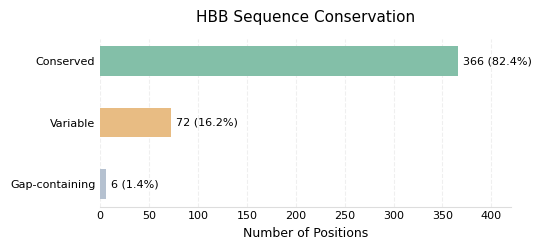

In [292]:
import matplotlib.pyplot as plt

categories = ["Conserved", "Variable", "Gap-containing"]
counts = [conserved, variable, gap_containing]
percentages = [count / total * 100 for count in counts]

colors = ["#83BFA8", "#E8BC83", "#B5C1D0"]

fig, ax = plt.subplots(figsize=(5.5, 2.6))

bars = ax.barh(
    categories,
    counts,
    color=colors,
    height=0.48
)

ax.invert_yaxis()
ax.set_xlim(0, 420)

ax.set_title("HBB Sequence Conservation", fontsize=11, pad=12)
ax.set_xlabel("Number of Positions", fontsize=9)

ax.tick_params(axis="both", labelsize=8, length=0)

# Add values and percentages
for bar, count, percentage in zip(bars, counts, percentages):
    ax.text(
        count + 5,
        bar.get_y() + bar.get_height() / 2,
        f"{count} ({percentage:.1f}%)",
        va="center",
        fontsize=8
    )

# Simplify the chart appearance
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.spines["left"].set_visible(False)
ax.spines["bottom"].set_color("#DDDDDD")

ax.grid(axis="x", linestyle="--", alpha=0.2)
ax.set_axisbelow(True)

plt.tight_layout()
plt.show()

In [293]:
# Identify variable nucleotide positions
variable_sites = []

for column in range(alignment.get_alignment_length()):
    bases = [str(record.seq[column]) for record in alignment]

    if "-" not in bases and len(set(bases)) > 1:
        variable_sites.append({
            "Position": column + 1,
            "Human": bases[0],
            "Chimpanzee": bases[1],
            "Cattle": bases[2],
            "Sheep": bases[3]
        })

# Display the first 10 variable positions
print("HBB — VARIABLE NUCLEOTIDE SITES")
print("-" * 55)

for site in variable_sites[:10]:
    print(
        f"Position {site['Position']:>3} | "
        f"Human: {site['Human']} | "
        f"Chimp: {site['Chimpanzee']} | "
        f"Cattle: {site['Cattle']} | "
        f"Sheep: {site['Sheep']}"
    )

print("-" * 55)
print("Total variable sites:", len(variable_sites))

HBB — VARIABLE NUCLEOTIDE SITES
-------------------------------------------------------
Position  16 | Human: c | Chimp: c | Cattle: g | Sheep: g
Position  28 | Human: t | Chimp: t | Cattle: g | Sheep: g
Position  36 | Human: t | Chimp: t | Cattle: c | Sheep: c
Position  39 | Human: t | Chimp: t | Cattle: c | Sheep: c
Position  41 | Human: c | Chimp: c | Cattle: c | Sheep: g
Position  43 | Human: c | Chimp: c | Cattle: t | Sheep: t
Position  45 | Human: g | Chimp: g | Cattle: t | Sheep: c
Position  60 | Human: c | Chimp: c | Cattle: a | Sheep: a
Position  77 | Human: g | Chimp: g | Cattle: g | Sheep: c
Position  81 | Human: g | Chimp: g | Cattle: g | Sheep: a
-------------------------------------------------------
Total variable sites: 72


In [294]:
# Classify substitutions relative to human HBB
transitions = 0
transversions = 0

transition_pairs = {"AG", "GA", "CT", "TC"}

for record in alignment[1:]:
    for human_base, other_base in zip(
        alignment[0].seq,
        record.seq
    ):
        human_base = str(human_base).upper()
        other_base = str(other_base).upper()

        if "-" in (human_base, other_base):
            continue

        if human_base != other_base:
            pair = human_base + other_base

            if pair in transition_pairs:
                transitions += 1
            else:
                transversions += 1

print("HBB — SUBSTITUTION CLASSIFICATION")
print("-" * 40)
print("Transitions:  ", transitions)
print("Transversions:", transversions)
print("Total differences:", transitions + transversions)

HBB — SUBSTITUTION CLASSIFICATION
----------------------------------------
Transitions:   72
Transversions: 51
Total differences: 123


In [295]:
# Compare substitution types separately for each species
transition_pairs = {"AG", "GA", "CT", "TC"}

print("SUBSTITUTION ANALYSIS BY SPECIES")
print("-" * 50)

for record in alignment[1:]:
    transitions = 0
    transversions = 0

    for human_base, other_base in zip(
        alignment[0].seq, record.seq
    ):
        human_base = str(human_base).upper()
        other_base = str(other_base).upper()

        if "-" in (human_base, other_base):
            continue

        if human_base != other_base:
            if human_base + other_base in transition_pairs:
                transitions += 1
            else:
                transversions += 1

    print(f"\n{record.id}")
    print(f"Transitions:   {transitions}")
    print(f"Transversions: {transversions}")
    print(f"Total:         {transitions + transversions}")

SUBSTITUTION ANALYSIS BY SPECIES
--------------------------------------------------

XM_508242.5
Transitions:   1
Transversions: 0
Total:         1

NM_173917.2
Transitions:   37
Transversions: 20
Total:         57

NM_001097648.1
Transitions:   34
Transversions: 31
Total:         65


In [296]:
# Calculate pairwise nucleotide identity relative to human
human_aligned = str(alignment[0].seq).upper()

print("HBB — PAIRWISE SEQUENCE IDENTITY")
print("-" * 45)

for record in alignment[1:]:
    other_sequence = str(record.seq).upper()

    comparable_positions = 0
    matching_positions = 0

    for human_base, other_base in zip(
        human_aligned, other_sequence
    ):
        if "-" in (human_base, other_base):
            continue

        comparable_positions += 1

        if human_base == other_base:
            matching_positions += 1

    identity = matching_positions / comparable_positions * 100

    print(f"\n{record.id}")
    print(f"Matching positions: {matching_positions}")
    print(f"Comparable positions: {comparable_positions}")
    print(f"Sequence identity: {identity:.2f}%")

HBB — PAIRWISE SEQUENCE IDENTITY
---------------------------------------------

XM_508242.5
Matching positions: 443
Comparable positions: 444
Sequence identity: 99.77%

NM_173917.2
Matching positions: 381
Comparable positions: 438
Sequence identity: 86.99%

NM_001097648.1
Matching positions: 373
Comparable positions: 438
Sequence identity: 85.16%


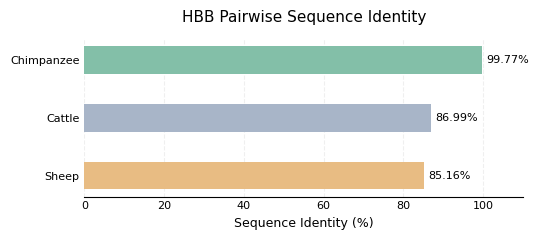

In [297]:
import matplotlib.pyplot as plt

species = ["Chimpanzee", "Cattle", "Sheep"]
identities = [99.77, 86.99, 85.16]

fig, ax = plt.subplots(figsize=(5.5, 2.5))

bars = ax.barh(
    species,
    identities,
    color=["#83BFA8", "#A8B5C8", "#E8BC83"],
    height=0.48
)

ax.invert_yaxis()
ax.set_xlim(0, 110)

ax.set_title("HBB Pairwise Sequence Identity", fontsize=11, pad=12)
ax.set_xlabel("Sequence Identity (%)", fontsize=9)

ax.tick_params(axis="both", labelsize=8, length=0)

for bar, value in zip(bars, identities):
    ax.text(
        value + 1,
        bar.get_y() + bar.get_height() / 2,
        f"{value:.2f}%",
        va="center",
        fontsize=8
    )

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.spines["left"].set_visible(False)
ax.grid(axis="x", linestyle="--", alpha=0.2)
ax.set_axisbelow(True)

plt.tight_layout()
plt.show()

In [298]:
# Compare translated HBB protein sequences

protein_sequences = {}

for species, data in hbb_dataset.items():
    protein_sequences[species] = str(
        Seq(data["sequence"]).translate()
    )

human_protein = protein_sequences["Human"].rstrip("*")

print("HBB PROTEIN SEQUENCES")
print("-" * 45)

for species, protein in protein_sequences.items():
    protein = protein.rstrip("*")

    matching = sum(
        a == b for a, b in zip(human_protein, protein)
    )

    comparable = min(len(human_protein), len(protein))
    identity = matching / comparable * 100

    print(f"\n{species}")
    print(f"Protein length: {len(protein)} amino acids")
    print(f"Matching amino acids: {matching}")
    print(f"Protein identity: {identity:.2f}%")

HBB PROTEIN SEQUENCES
---------------------------------------------

Human
Protein length: 147 amino acids
Matching amino acids: 147
Protein identity: 100.00%

Chimpanzee
Protein length: 147 amino acids
Matching amino acids: 147
Protein identity: 100.00%

Cattle
Protein length: 145 amino acids
Matching amino acids: 8
Protein identity: 5.52%

Sheep
Protein length: 145 amino acids
Matching amino acids: 9
Protein identity: 6.21%


In [299]:

# Compare original and alignment-based protein identity

print("PROTEIN IDENTITY COMPARISON")
print("-" * 45)

human_aligned = str(next(
    record.seq for record in protein_alignment
    if record.id == "Human"
))

for species in protein_sequences:

    protein_aligned = str(next(
        record.seq for record in protein_alignment
        if record.id == species
    ))

    # Original method
    human_original = protein_sequences["Human"]
    species_original = protein_sequences[species]

    old_matches = sum(
        a == b for a, b in zip(human_original, species_original)
    )

    old_identity = old_matches / min(
        len(human_original), len(species_original)
    ) * 100

    # Alignment-based method
    comparable = sum(
        a != "-" and b != "-"
        for a, b in zip(human_aligned, protein_aligned)
    )

    new_matches = sum(
        a == b for a, b in zip(human_aligned, protein_aligned)
        if a != "-" and b != "-"
    )

    new_identity = new_matches / comparable * 100

    print(f"\n{species}")
    print(f"Original identity: {old_identity:.2f}%")
    print(f"Aligned identity: {new_identity:.2f}%")


PROTEIN IDENTITY COMPARISON
---------------------------------------------

Human
Original identity: 100.00%
Aligned identity: 100.00%

Chimpanzee
Original identity: 100.00%
Aligned identity: 100.00%

Cattle
Original identity: 5.48%
Aligned identity: 84.83%

Sheep
Original identity: 6.16%
Aligned identity: 81.38%


In [300]:
from Bio.SeqRecord import SeqRecord

# Create protein FASTA records
protein_records = []

for species, protein in protein_sequences.items():
    clean_protein = protein.rstrip("*")

    record = SeqRecord(
        Seq(clean_protein),
        id=species,
        description=""
    )

    protein_records.append(record)

# Save protein sequences
SeqIO.write(
    protein_records,
    "hbb_proteins.fasta",
    "fasta"
)

print("Protein FASTA file created successfully.")
print(f"Number of protein sequences: {len(protein_records)}")

Protein FASTA file created successfully.
Number of protein sequences: 4


In [301]:
!mafft --auto hbb_proteins.fasta > hbb_protein_alignment.fasta

outputhat23=16
treein = 0
compacttree = 0
stacksize: 8192 kb
rescale = 1
All-to-all alignment.
tbfast-pair (aa) Version 7.505
alg=L, model=BLOSUM62, 2.00, -0.10, +0.10, noshift, amax=0.0
0 thread(s)

outputhat23=16
Loading 'hat3.seed' ... 
done.
Writing hat3 for iterative refinement
rescale = 1
Gap Penalty = -1.53, +0.00, +0.00
tbutree = 1, compacttree = 0
Constructing a UPGMA tree ... 
    0 / 4
done.

Progressive alignment ... 
STEP     3 /3 
done.
tbfast (aa) Version 7.505
alg=A, model=BLOSUM62, 1.53, -0.00, -0.00, noshift, amax=0.0
1 thread(s)

minimumweight = 0.000010
autosubalignment = 0.000000
nthread = 0
randomseed = 0
blosum 62 / kimura 200
poffset = 0
niter = 16
sueff_global = 0.100000
nadd = 16
Loading 'hat3' ... done.
rescale = 1

    0 / 4
Segment   1/  1    1- 148
STEP 003-002-0  identical.   
Converged.

done
dvtditr (aa) Version 7.505
alg=A, model=BLOSUM62, 1.53, -0.00, -0.00, noshift, amax=0.0
0 thread(s)


Strategy:
 L-INS-i (Probably most accurate, very slow)
 Iterat

In [302]:
# Read the aligned protein sequences

protein_alignment = AlignIO.read(
    "hbb_protein_alignment.fasta",
    "fasta"
)

print("HBB PROTEIN ALIGNMENT")
print("-" * 45)

print(f"Number of sequences: {len(protein_alignment)}")
print(f"Alignment length: {protein_alignment.get_alignment_length()} positions")

for record in protein_alignment:
    sequence = str(record.seq)

    print(
        f"{record.id}: "
        f"{len(sequence)} positions | "
        f"{sequence.count('-')} gaps"
    )

HBB PROTEIN ALIGNMENT
---------------------------------------------
Number of sequences: 4
Alignment length: 147 positions
Human: 147 positions | 0 gaps
Chimpanzee: 147 positions | 0 gaps
Cattle: 147 positions | 2 gaps
Sheep: 147 positions | 2 gaps


In [303]:
# Calculate protein identity relative to human

human_aligned_protein = str(
    protein_alignment[0].seq
).upper()

print("HBB — PROTEIN SEQUENCE IDENTITY")
print("-" * 45)

for record in protein_alignment[1:]:
    other_protein = str(record.seq).upper()

    comparable_positions = 0
    matching_positions = 0

    for human_aa, other_aa in zip(
        human_aligned_protein, other_protein
    ):
        if "-" in (human_aa, other_aa):
            continue

        comparable_positions += 1

        if human_aa == other_aa:
            matching_positions += 1

    identity = (
        matching_positions / comparable_positions
    ) * 100

    print(f"\n{record.id}")
    print(f"Matching amino acids: {matching_positions}")
    print(f"Comparable positions: {comparable_positions}")
    print(f"Protein identity: {identity:.2f}%")

HBB — PROTEIN SEQUENCE IDENTITY
---------------------------------------------

Chimpanzee
Matching amino acids: 147
Comparable positions: 147
Protein identity: 100.00%

Cattle
Matching amino acids: 123
Comparable positions: 145
Protein identity: 84.83%

Sheep
Matching amino acids: 118
Comparable positions: 145
Protein identity: 81.38%


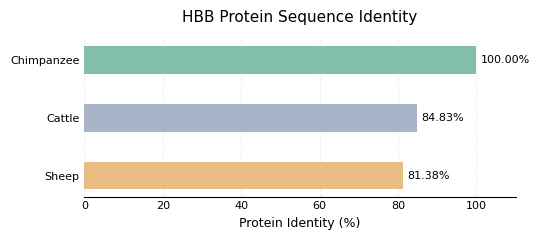

In [304]:
import matplotlib.pyplot as plt

species = ["Chimpanzee", "Cattle", "Sheep"]
identities = [100.00, 84.83, 81.38]

fig, ax = plt.subplots(figsize=(5.5, 2.5))

bars = ax.barh(
    species,
    identities,
    color=["#83BFA8", "#A8B5C8", "#E8BC83"],
    height=0.48
)

ax.invert_yaxis()
ax.set_xlim(0, 110)

ax.set_title("HBB Protein Sequence Identity", fontsize=11, pad=12)
ax.set_xlabel("Protein Identity (%)", fontsize=9)

ax.tick_params(axis="both", labelsize=8, length=0)

for bar, value in zip(bars, identities):
    ax.text(
        value + 1,
        bar.get_y() + bar.get_height() / 2,
        f"{value:.2f}%",
        va="center",
        fontsize=8
    )

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.spines["left"].set_visible(False)
ax.grid(axis="x", linestyle="--", alpha=0.2)
ax.set_axisbelow(True)

plt.tight_layout()
plt.show()

In [305]:
# Identify amino-acid substitutions relative to human HBB

human_protein_aligned = str(
    protein_alignment[0].seq
).upper()

print("HBB — AMINO-ACID SUBSTITUTIONS")
print("-" * 55)

for record in protein_alignment[1:]:
    species_protein = str(record.seq).upper()

    substitutions = []
    gap_positions = []

    for position, (human_aa, species_aa) in enumerate(
        zip(human_protein_aligned, species_protein),
        start=1
    ):
        if "-" in (human_aa, species_aa):
            gap_positions.append(position)

        elif human_aa != species_aa:
            substitutions.append(
                (position, human_aa, species_aa)
            )

    print(f"\n{record.id}")
    print(f"Number of substitutions: {len(substitutions)}")
    print(f"Number of gap positions: {len(gap_positions)}")

    for position, human_aa, species_aa in substitutions:
        print(
            f"Position {position}: "
            f"Human {human_aa} → {record.id} {species_aa}"
        )

    print(f"Gap positions: {gap_positions}")

HBB — AMINO-ACID SUBSTITUTIONS
-------------------------------------------------------

Chimpanzee
Number of substitutions: 0
Number of gap positions: 0
Gap positions: []

Cattle
Number of substitutions: 22
Number of gap positions: 2
Position 6: Human P → Cattle A
Position 10: Human S → Cattle A
Position 15: Human L → Cattle F
Position 20: Human N → Cattle K
Position 52: Human P → Cattle A
Position 57: Human G → Cattle N
Position 70: Human G → Cattle D
Position 71: Human A → Cattle S
Position 74: Human D → Cattle N
Position 76: Human L → Cattle M
Position 77: Human A → Cattle K
Position 81: Human N → Cattle D
Position 88: Human T → Cattle A
Position 105: Human R → Cattle K
Position 113: Human C → Cattle V
Position 117: Human H → Cattle R
Position 118: Human H → Cattle N
Position 126: Human P → Cattle V
Position 127: Human V → Cattle L
Position 130: Human A → Cattle D
Position 131: Human Y → Cattle F
Position 145: Human K → Cattle R
Gap positions: [2, 3]

Sheep
Number of substitutions: 

In [306]:
# Compare amino-acid substitutions between cattle and sheep

substitution_data = {}

human_protein = str(protein_alignment[0].seq).upper()

for record in protein_alignment[1:]:
    species_protein = str(record.seq).upper()

    substitutions = set()

    for position, (human_aa, species_aa) in enumerate(
        zip(human_protein, species_protein),
        start=1
    ):
        if human_aa != "-" and species_aa != "-":
            if human_aa != species_aa:
                substitutions.add(
                    (position, human_aa, species_aa)
                )

    substitution_data[record.id] = substitutions


# Retrieve substitutions using species names
cattle_substitutions = substitution_data["Cattle"]
sheep_substitutions = substitution_data["Sheep"]


# Identify shared and species-specific substitutions
shared = cattle_substitutions & sheep_substitutions

cattle_unique = cattle_substitutions - sheep_substitutions

sheep_unique = sheep_substitutions - cattle_substitutions


# Display results
print("SHARED AND SPECIES-SPECIFIC SUBSTITUTIONS")
print("-" * 55)

print(f"\nShared substitutions: {len(shared)}")
for position, human_aa, other_aa in sorted(shared):
    print(f"Position {position}: {human_aa} → {other_aa}")

print(f"\nCattle-specific substitutions: {len(cattle_unique)}")
for position, human_aa, other_aa in sorted(cattle_unique):
    print(f"Position {position}: {human_aa} → {other_aa}")

print(f"\nSheep-specific substitutions: {len(sheep_unique)}")
for position, human_aa, other_aa in sorted(sheep_unique):
    print(f"Position {position}: {human_aa} → {other_aa}")

SHARED AND SPECIES-SPECIFIC SUBSTITUTIONS
-------------------------------------------------------

Shared substitutions: 16
Position 6: P → A
Position 10: S → A
Position 15: L → F
Position 20: N → K
Position 52: P → A
Position 57: G → N
Position 70: G → D
Position 71: A → S
Position 74: D → N
Position 81: N → D
Position 113: C → V
Position 117: H → R
Position 126: P → V
Position 127: V → L
Position 131: Y → F
Position 145: K → R

Cattle-specific substitutions: 6
Position 76: L → M
Position 77: A → K
Position 88: T → A
Position 105: R → K
Position 118: H → N
Position 130: A → D

Sheep-specific substitutions: 11
Position 14: A → G
Position 26: G → A
Position 45: S → H
Position 51: T → S
Position 59: P → A
Position 76: L → V
Position 77: A → Q
Position 88: T → Q
Position 119: F → H
Position 121: K → S
Position 130: A → E


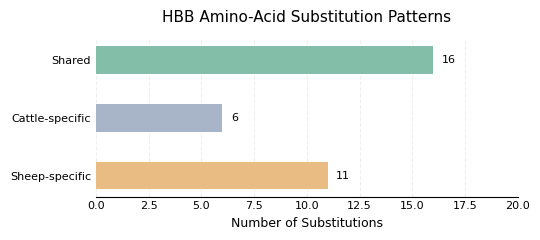

In [307]:
import matplotlib.pyplot as plt

categories = [
    "Shared",
    "Cattle-specific",
    "Sheep-specific"
]

counts = [len(shared), len(cattle_unique), len(sheep_unique)]

fig, ax = plt.subplots(figsize=(5.5, 2.5))

bars = ax.barh(
    categories,
    counts,
    color=["#83BFA8", "#A8B5C8", "#E8BC83"],
    height=0.48
)

ax.invert_yaxis()
ax.set_xlim(0, 20)

ax.set_title(
    "HBB Amino-Acid Substitution Patterns",
    fontsize=11,
    pad=12
)

ax.set_xlabel("Number of Substitutions", fontsize=9)
ax.tick_params(axis="both", labelsize=8, length=0)

for bar, value in zip(bars, counts):
    ax.text(
        value + 0.4,
        bar.get_y() + bar.get_height() / 2,
        str(value),
        va="center",
        fontsize=8
    )

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.spines["left"].set_visible(False)

ax.grid(axis="x", linestyle="--", alpha=0.2)
ax.set_axisbelow(True)

plt.tight_layout()
plt.show()

In [308]:
# Classify amino-acid substitutions by chemical properties

amino_acid_groups = {
    "Nonpolar aliphatic": set("AVILM"),
    "Aromatic": set("FWY"),
    "Polar uncharged": set("STNQ"),
    "Positive": set("KRH"),
    "Negative": set("DE"),
    "Special structural": set("GPC")
}

def get_amino_acid_group(amino_acid):
    for group, amino_acids in amino_acid_groups.items():
        if amino_acid in amino_acids:
            return group
    return "Unknown"


print("HBB — SUBSTITUTION PROPERTY CLASSIFICATION")
print("-" * 55)

for species in ["Cattle", "Sheep"]:

    print(f"\n{species}")

    conservative = 0
    non_conservative = 0

    for position, human_aa, species_aa in sorted(
        substitution_data[species]
    ):

        human_group = get_amino_acid_group(human_aa)
        species_group = get_amino_acid_group(species_aa)

        if human_group == species_group:
            conservative += 1
            classification = "Same chemical group"
        else:
            non_conservative += 1
            classification = "Different chemical group"

        print(
            f"Position {position}: "
            f"{human_aa} → {species_aa} | "
            f"{human_group} → {species_group} | "
            f"{classification}"
        )

    print(f"\nSame-group substitutions: {conservative}")
    print(f"Different-group substitutions: {non_conservative}")

HBB — SUBSTITUTION PROPERTY CLASSIFICATION
-------------------------------------------------------

Cattle
Position 6: P → A | Special structural → Nonpolar aliphatic | Different chemical group
Position 10: S → A | Polar uncharged → Nonpolar aliphatic | Different chemical group
Position 15: L → F | Nonpolar aliphatic → Aromatic | Different chemical group
Position 20: N → K | Polar uncharged → Positive | Different chemical group
Position 52: P → A | Special structural → Nonpolar aliphatic | Different chemical group
Position 57: G → N | Special structural → Polar uncharged | Different chemical group
Position 70: G → D | Special structural → Negative | Different chemical group
Position 71: A → S | Nonpolar aliphatic → Polar uncharged | Different chemical group
Position 74: D → N | Negative → Polar uncharged | Different chemical group
Position 76: L → M | Nonpolar aliphatic → Nonpolar aliphatic | Same chemical group
Position 77: A → K | Nonpolar aliphatic → Positive | Different chemical gr

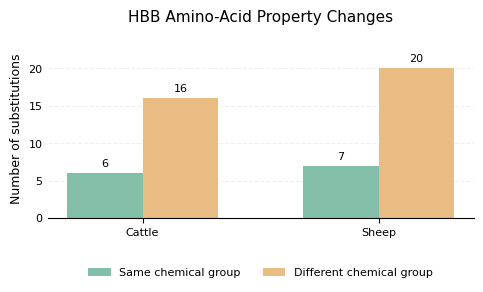

In [309]:
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.patches import Patch

species = ["Cattle", "Sheep"]

same_group = [6, 7]
different_group = [16, 20]

x = np.arange(len(species))
width = 0.32

fig, ax = plt.subplots(figsize=(5.5, 3.1))

bars1 = ax.bar(
    x - width / 2,
    same_group,
    width,
    color="#83BFA8"
)

bars2 = ax.bar(
    x + width / 2,
    different_group,
    width,
    color="#E8BC83"
)

ax.set_title(
    "HBB Amino-Acid Property Changes",
    fontsize=11,
    pad=12
)

ax.set_ylabel("Number of substitutions", fontsize=9)
ax.set_xticks(x)
ax.set_xticklabels(species, fontsize=8)
ax.set_ylim(0, 24)

ax.tick_params(axis="y", labelsize=8, length=0)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.spines["left"].set_visible(False)

ax.grid(axis="y", linestyle="--", alpha=0.2)
ax.set_axisbelow(True)

ax.bar_label(bars1, padding=3, fontsize=8)
ax.bar_label(bars2, padding=3, fontsize=8)

# Figure legend below the graph
legend_elements = [
    Patch(
        facecolor="#83BFA8",
        label="Same chemical group"
    ),
    Patch(
        facecolor="#E8BC83",
        label="Different chemical group"
    )
]

ax.legend(
    handles=legend_elements,
    loc="upper center",
    bbox_to_anchor=(0.5, -0.22),
    ncol=2,
    frameon=False,
    fontsize=8
)

plt.subplots_adjust(bottom=0.30)
plt.show()

HBB PROTEIN DISTANCE MATRIX
Human   0.000000
Chimpanzee  0.000000    0.000000
Cattle  0.151724    0.151724    0.000000
Sheep   0.186207    0.186207    0.089655    0.000000
    Human   Chimpanzee  Cattle  Sheep


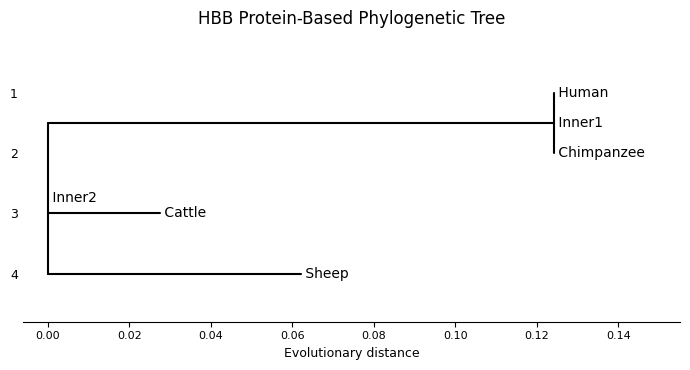

In [310]:
# Construct and visualize a protein-based phylogenetic tree

from Bio.Phylo.TreeConstruction import DistanceMatrix, DistanceTreeConstructor
from Bio import Phylo
import matplotlib.pyplot as plt

# 1. Prepare aligned protein sequences
records = list(protein_alignment)
names = [record.id for record in records]

# 2. Calculate pairwise evolutionary distances
distance_matrix = []

for i, record1 in enumerate(records):
    sequence1 = str(record1.seq).upper()
    distances = []

    for j in range(i + 1):
        sequence2 = str(records[j].seq).upper()

        if i == j:
            distances.append(0.0)
            continue

        # Compare only positions without alignment gaps
        comparable = [
            (aa1, aa2)
            for aa1, aa2 in zip(sequence1, sequence2)
            if aa1 != "-" and aa2 != "-"
        ]

        differences = sum(
            aa1 != aa2 for aa1, aa2 in comparable
        )

        distance = differences / len(comparable)
        distances.append(distance)

    distance_matrix.append(distances)

# 3. Display the distance matrix
matrix = DistanceMatrix(names, distance_matrix)

print("HBB PROTEIN DISTANCE MATRIX")
print("=" * 55)
print(matrix)

# 4. Construct the Neighbor-Joining tree
constructor = DistanceTreeConstructor()
phylogenetic_tree = constructor.nj(matrix)

# 5. Visualize the phylogenetic tree
fig, ax = plt.subplots(figsize=(7, 3.8))

Phylo.draw(
    phylogenetic_tree,
    axes=ax,
    do_show=False,
    show_confidence=False
)

ax.set_title(
    "HBB Protein-Based Phylogenetic Tree",
    fontsize=12,
    pad=15
)

ax.set_xlabel("Evolutionary distance", fontsize=9)

# Clean up the appearance
ax.set_ylabel("")
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.spines["left"].set_visible(False)
ax.tick_params(axis="y", labelsize=9, length=0)
ax.tick_params(axis="x", labelsize=8)

plt.tight_layout()
plt.show()

In [311]:
# Summarize phylogenetic relationships

print("PHYLOGENETIC RELATIONSHIP SUMMARY")
print("=" * 50)

# Calculate pairwise evolutionary distances
records = list(protein_alignment)

for i in range(len(records)):
    for j in range(i + 1, len(records)):

        sequence1 = str(records[i].seq).upper()
        sequence2 = str(records[j].seq).upper()

        comparable = [
            (aa1, aa2)
            for aa1, aa2 in zip(sequence1, sequence2)
            if aa1 != "-" and aa2 != "-"
        ]

        differences = sum(
            aa1 != aa2 for aa1, aa2 in comparable
        )

        distance = differences / len(comparable)

        print(
            f"{records[i].id} vs {records[j].id}: "
            f"{distance:.4f}"
        )

# Identify the closest pair
print("\nCLOSEST SEQUENCE PAIR")
print("-" * 50)

pairwise_distances = []

for i in range(len(records)):
    for j in range(i + 1, len(records)):

        sequence1 = str(records[i].seq).upper()
        sequence2 = str(records[j].seq).upper()

        comparable = [
            (aa1, aa2)
            for aa1, aa2 in zip(sequence1, sequence2)
            if aa1 != "-" and aa2 != "-"
        ]

        differences = sum(
            aa1 != aa2 for aa1, aa2 in comparable
        )

        distance = differences / len(comparable)

        pairwise_distances.append(
            (records[i].id, records[j].id, distance)
        )

closest_pair = min(pairwise_distances, key=lambda x: x[2])

print(f"Species: {closest_pair[0]} and {closest_pair[1]}")
print(f"Evolutionary distance: {closest_pair[2]:.4f}")

PHYLOGENETIC RELATIONSHIP SUMMARY
Human vs Chimpanzee: 0.0000
Human vs Cattle: 0.1517
Human vs Sheep: 0.1862
Chimpanzee vs Cattle: 0.1517
Chimpanzee vs Sheep: 0.1862
Cattle vs Sheep: 0.0897

CLOSEST SEQUENCE PAIR
--------------------------------------------------
Species: Human and Chimpanzee
Evolutionary distance: 0.0000


### Interpretation

The protein-based comparison revealed that human and chimpanzee HBB sequences are identical in the analyzed dataset, showing the highest level of sequence similarity.

Cattle and sheep also showed relatively high similarity to each other, with an evolutionary distance of 0.0897.

Overall, the results indicate that HBB protein sequences are highly conserved across the four species, although differences are present between the primate and livestock sequences.

These findings describe sequence-level similarities and should not be interpreted as a complete species evolutionary history.

In [312]:
# Compare GC content across species

gc_content = {}

for species, data in hbb_dataset.items():
    sequence = data["sequence"].upper()

    gc_count = sequence.count("G") + sequence.count("C")
    gc_percentage = (gc_count / len(sequence)) * 100

    gc_content[species] = gc_percentage

# Display results
print("HBB GC CONTENT COMPARISON")
print("=" * 40)

for species, percentage in gc_content.items():
    print(f"{species}: {percentage:.2f}%")

HBB GC CONTENT COMPARISON
Human: 56.08%
Chimpanzee: 56.31%
Cattle: 53.88%
Sheep: 55.94%


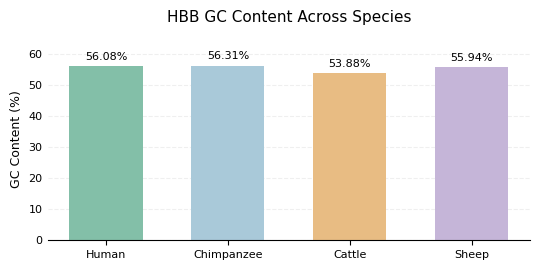

In [313]:
import matplotlib.pyplot as plt

species = list(gc_content.keys())
values = list(gc_content.values())

fig, ax = plt.subplots(figsize=(5.5, 2.8))

bars = ax.bar(
    species,
    values,
    color=["#83BFA8", "#A9C9D9", "#E8BC83", "#C5B5D8"],
    width=0.6
)

ax.set_title("HBB GC Content Across Species", fontsize=11, pad=12)
ax.set_ylabel("GC Content (%)", fontsize=9)
ax.set_ylim(0, 65)

ax.tick_params(axis="x", labelsize=8)
ax.tick_params(axis="y", labelsize=8, length=0)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.spines["left"].set_visible(False)

ax.grid(axis="y", linestyle="--", alpha=0.2)
ax.set_axisbelow(True)

ax.bar_label(bars, fmt="%.2f%%", padding=3, fontsize=8)

plt.tight_layout()
plt.show()

In [314]:
at_content = {}

for species, data in hbb_dataset.items():
    sequence = data["sequence"].upper()

    at_count = sequence.count("A") + sequence.count("T")
    at_percentage = (at_count / len(sequence)) * 100

    at_content[species] = at_percentage

print("HBB AT CONTENT COMPARISON")
print("=" * 40)

for species, percentage in at_content.items():
    print(f"{species}: {percentage:.2f}%")

HBB AT CONTENT COMPARISON
Human: 43.92%
Chimpanzee: 43.69%
Cattle: 46.12%
Sheep: 44.06%


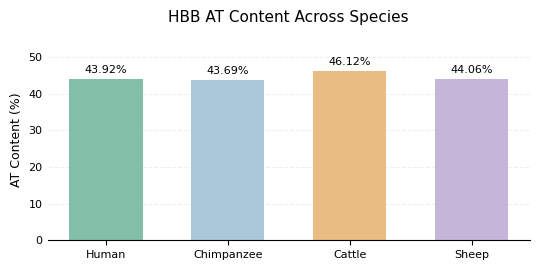

In [315]:
import matplotlib.pyplot as plt

species = list(at_content.keys())
values = list(at_content.values())

fig, ax = plt.subplots(figsize=(5.5, 2.8))

bars = ax.bar(
    species,
    values,
    color=["#83BFA8", "#A9C9D9", "#E8BC83", "#C5B5D8"],
    width=0.6
)

ax.set_title("HBB AT Content Across Species", fontsize=11, pad=12)
ax.set_ylabel("AT Content (%)", fontsize=9)
ax.set_ylim(0, 55)

ax.tick_params(axis="x", labelsize=8)
ax.tick_params(axis="y", labelsize=8, length=0)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.spines["left"].set_visible(False)

ax.grid(axis="y", linestyle="--", alpha=0.2)
ax.set_axisbelow(True)

ax.bar_label(bars, fmt="%.2f%%", padding=3, fontsize=8)

plt.tight_layout()
plt.show()

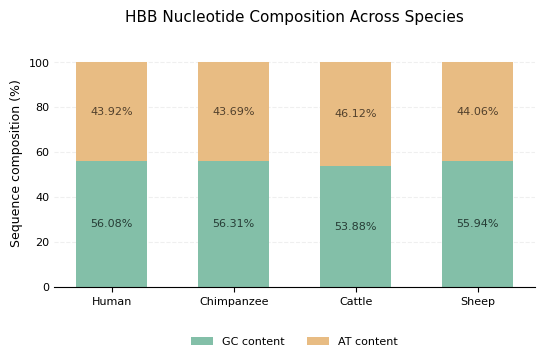

NUCLEOTIDE COMPOSITION SUMMARY
Human        | GC: 56.08% | AT: 43.92% | Total: 100.00%
Chimpanzee   | GC: 56.31% | AT: 43.69% | Total: 100.00%
Cattle       | GC: 53.88% | AT: 46.12% | Total: 100.00%
Sheep        | GC: 55.94% | AT: 44.06% | Total: 100.00%

KEY FINDINGS
-------------------------------------------------------
Highest GC content: Chimpanzee (56.31%)
Lowest GC content: Cattle (53.88%)
GC content difference: 2.43 percentage points


In [316]:
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.patches import Patch

species = list(gc_content.keys())
gc_values = list(gc_content.values())
at_values = list(at_content.values())

x = np.arange(len(species))
width = 0.58

fig, ax = plt.subplots(figsize=(6.2, 3.8))

gc_bars = ax.bar(
    x, gc_values, width,
    color="#83BFA8"
)

at_bars = ax.bar(
    x, at_values, width,
    bottom=gc_values,
    color="#E8BC83"
)

# Add exact percentages inside each section
for i in range(len(species)):
    ax.text(
        x[i], gc_values[i] / 2,
        f"{gc_values[i]:.2f}%",
        ha="center", va="center",
        fontsize=8, color="#263C35"
    )

    ax.text(
        x[i], gc_values[i] + at_values[i] / 2,
        f"{at_values[i]:.2f}%",
        ha="center", va="center",
        fontsize=8, color="#51402C"
    )

ax.set_title(
    "HBB Nucleotide Composition Across Species",
    fontsize=11, pad=13
)

ax.set_ylabel("Sequence composition (%)", fontsize=9)
ax.set_xticks(x)
ax.set_xticklabels(species, fontsize=8)
ax.set_ylim(0, 110)

ax.tick_params(axis="y", labelsize=8, length=0)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.spines["left"].set_visible(False)

ax.grid(axis="y", linestyle="--", alpha=0.2)
ax.set_axisbelow(True)

legend_elements = [
    Patch(facecolor="#83BFA8", label="GC content"),
    Patch(facecolor="#E8BC83", label="AT content")
]

ax.legend(
    handles=legend_elements,
    loc="upper center",
    bbox_to_anchor=(0.5, -0.16),
    ncol=2,
    frameon=False,
    fontsize=8
)

plt.subplots_adjust(bottom=0.23)
plt.show()

# Numerical comparison
print("NUCLEOTIDE COMPOSITION SUMMARY")
print("=" * 55)

for species_name in species:
    gc = gc_content[species_name]
    at = at_content[species_name]

    print(
        f"{species_name:12} | "
        f"GC: {gc:5.2f}% | "
        f"AT: {at:5.2f}% | "
        f"Total: {gc + at:.2f}%"
    )

highest_gc = max(gc_content, key=gc_content.get)
lowest_gc = min(gc_content, key=gc_content.get)

print("\nKEY FINDINGS")
print("-" * 55)
print(f"Highest GC content: {highest_gc} ({gc_content[highest_gc]:.2f}%)")
print(f"Lowest GC content: {lowest_gc} ({gc_content[lowest_gc]:.2f}%)")
print(f"GC content difference: {gc_content[highest_gc] - gc_content[lowest_gc]:.2f} percentage points")

In [317]:
# Identify conserved and variable amino acid positions

protein_length = protein_alignment.get_alignment_length()

conserved_positions = []
variable_positions = []

for position in range(protein_length):
    amino_acids = [
        record.seq[position]
        for record in protein_alignment
    ]

    if "-" in amino_acids:
        continue

    if len(set(amino_acids)) == 1:
        conserved_positions.append(position + 1)
    else:
        variable_positions.append(position + 1)

print("HBB PROTEIN CONSERVATION ANALYSIS")
print("=" * 50)

print(f"Total alignment positions: {protein_length}")
print(f"Conserved positions: {len(conserved_positions)}")
print(f"Variable positions: {len(variable_positions)}")

conserved_percentage = (
    len(conserved_positions) / protein_length
) * 100

variable_percentage = (
    len(variable_positions) / protein_length
) * 100

print(f"\nConserved percentage: {conserved_percentage:.2f}%")
print(f"Variable percentage: {variable_percentage:.2f}%")

HBB PROTEIN CONSERVATION ANALYSIS
Total alignment positions: 147
Conserved positions: 116
Variable positions: 29

Conserved percentage: 78.91%
Variable percentage: 19.73%


In [318]:
# Corrected protein conservation analysis

conserved_aa = 0
variable_aa = 0
gap_aa = 0

for column in range(protein_alignment.get_alignment_length()):
    amino_acids = [
        str(record.seq[column])
        for record in protein_alignment
    ]

    if "-" in amino_acids:
        gap_aa += 1
    elif len(set(amino_acids)) == 1:
        conserved_aa += 1
    else:
        variable_aa += 1

comparable_positions = conserved_aa + variable_aa
conservation_percentage = (
    conserved_aa / comparable_positions * 100
)

print("PROTEIN CONSERVATION ANALYSIS")
print("-" * 40)
print("Total alignment positions:", protein_alignment.get_alignment_length())
print("Conserved positions:", conserved_aa)
print("Variable positions:", variable_aa)
print("Gap-containing positions:", gap_aa)
print(f"Conservation percentage: {conservation_percentage:.2f}%")


PROTEIN CONSERVATION ANALYSIS
----------------------------------------
Total alignment positions: 147
Conserved positions: 116
Variable positions: 29
Gap-containing positions: 2
Conservation percentage: 80.00%


In [319]:
# Calculate protein conservation percentages

total_positions = protein_alignment.get_alignment_length()
gap_positions = total_positions - len(conserved_positions) - len(variable_positions)

comparable_positions = len(conserved_positions) + len(variable_positions)

conserved_percentage = (
    len(conserved_positions) / comparable_positions
) * 100

variable_percentage = (
    len(variable_positions) / comparable_positions
) * 100

print("HBB PROTEIN CONSERVATION ANALYSIS")
print("=" * 50)

print(f"Total alignment positions: {total_positions}")
print(f"Conserved positions: {len(conserved_positions)}")
print(f"Variable positions: {len(variable_positions)}")
print(f"Gap-containing positions: {gap_positions}")
print(f"Comparable positions: {comparable_positions}")

print(f"\nConserved: {conserved_percentage:.2f}%")
print(f"Variable: {variable_percentage:.2f}%")

HBB PROTEIN CONSERVATION ANALYSIS
Total alignment positions: 147
Conserved positions: 116
Variable positions: 29
Gap-containing positions: 2
Comparable positions: 145

Conserved: 80.00%
Variable: 20.00%


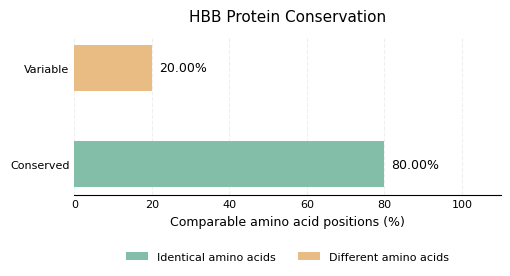

In [320]:
import matplotlib.pyplot as plt
from matplotlib.patches import Patch

categories = ["Conserved", "Variable"]
values = [conserved_percentage, variable_percentage]

fig, ax = plt.subplots(figsize=(5.5, 2.8))

bars = ax.barh(
    categories,
    values,
    color=["#83BFA8", "#E8BC83"],
    height=0.48
)

ax.set_title("HBB Protein Conservation", fontsize=11, pad=12)
ax.set_xlabel("Comparable amino acid positions (%)", fontsize=9)
ax.set_xlim(0, 110)

ax.bar_label(
    bars,
    labels=[f"{value:.2f}%" for value in values],
    padding=5,
    fontsize=9
)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.spines["left"].set_visible(False)
ax.tick_params(axis="both", labelsize=8, length=0)

ax.grid(axis="x", linestyle="--", alpha=0.2)
ax.set_axisbelow(True)

legend_elements = [
    Patch(facecolor="#83BFA8", label="Identical amino acids"),
    Patch(facecolor="#E8BC83", label="Different amino acids")
]

ax.legend(
    handles=legend_elements,
    loc="upper center",
    bbox_to_anchor=(0.5, -0.30),
    ncol=2,
    frameon=False,
    fontsize=8
)

plt.subplots_adjust(bottom=0.32)
plt.show()

In [321]:
# Identify the most variable amino acid positions

variable_details = []

for position in variable_positions:
    amino_acids = [
        str(record.seq[position - 1])
        for record in protein_alignment
    ]

    unique_amino_acids = sorted(set(amino_acids))

    variable_details.append({
        "Position": position,
        "Different amino acids": len(unique_amino_acids),
        "Human": amino_acids[0],
        "Chimpanzee": amino_acids[1],
        "Cattle": amino_acids[2],
        "Sheep": amino_acids[3]
    })

# Sort positions by the number of different amino acids
variable_details.sort(
    key=lambda item: item["Different amino acids"],
    reverse=True
)

print("MOST VARIABLE HBB PROTEIN POSITIONS")
print("=" * 75)

for item in variable_details:
    print(
        f"Position {item['Position']:3} | "
        f"Different amino acids: {item['Different amino acids']} | "
        f"Human: {item['Human']} | "
        f"Chimpanzee: {item['Chimpanzee']} | "
        f"Cattle: {item['Cattle']} | "
        f"Sheep: {item['Sheep']}"
    )

MOST VARIABLE HBB PROTEIN POSITIONS
Position  76 | Different amino acids: 3 | Human: L | Chimpanzee: L | Cattle: M | Sheep: V
Position  77 | Different amino acids: 3 | Human: A | Chimpanzee: A | Cattle: K | Sheep: Q
Position  88 | Different amino acids: 3 | Human: T | Chimpanzee: T | Cattle: A | Sheep: Q
Position 130 | Different amino acids: 3 | Human: A | Chimpanzee: A | Cattle: D | Sheep: E
Position   6 | Different amino acids: 2 | Human: P | Chimpanzee: P | Cattle: A | Sheep: A
Position  10 | Different amino acids: 2 | Human: S | Chimpanzee: S | Cattle: A | Sheep: A
Position  14 | Different amino acids: 2 | Human: A | Chimpanzee: A | Cattle: A | Sheep: G
Position  15 | Different amino acids: 2 | Human: L | Chimpanzee: L | Cattle: F | Sheep: F
Position  20 | Different amino acids: 2 | Human: N | Chimpanzee: N | Cattle: K | Sheep: K
Position  26 | Different amino acids: 2 | Human: G | Chimpanzee: G | Cattle: G | Sheep: A
Position  45 | Different amino acids: 2 | Human: S | Chimpanzee:

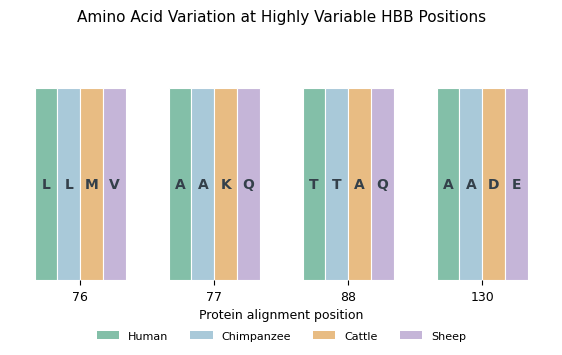

COMPARATIVE HBB AMINO ACID ANALYSIS

Alignment position: 76
----------------------------------------
Human       : L
Chimpanzee  : L
Cattle      : M
Sheep       : V
Distinct amino acids: 3

Alignment position: 77
----------------------------------------
Human       : A
Chimpanzee  : A
Cattle      : K
Sheep       : Q
Distinct amino acids: 3

Alignment position: 88
----------------------------------------
Human       : T
Chimpanzee  : T
Cattle      : A
Sheep       : Q
Distinct amino acids: 3

Alignment position: 130
----------------------------------------
Human       : A
Chimpanzee  : A
Cattle      : D
Sheep       : E
Distinct amino acids: 3

KEY FINDINGS
Human and chimpanzee share identical amino acids
at all four highly variable positions.

Cattle and sheep differ from the human reference
at all four positions.

Each position contains three distinct amino acids.

These observations describe sequence variation,
not experimentally established functional effects.


In [322]:
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.patches import Patch

# Select the four most variable positions
top_positions = [
    item for item in variable_details
    if item["Different amino acids"] == 3
]

species = ["Human", "Chimpanzee", "Cattle", "Sheep"]

colors = {
    "Human": "#83BFA8",
    "Chimpanzee": "#A9C9D9",
    "Cattle": "#E8BC83",
    "Sheep": "#C5B5D8"
}

# Prepare amino acid data
positions = [item["Position"] for item in top_positions]

amino_acids = {
    species_name: [
        item[species_name] for item in top_positions
    ]
    for species_name in species
}

# Create visualization
fig, ax = plt.subplots(figsize=(7, 3.8))

x = np.arange(len(positions))
width = 0.17

for i, species_name in enumerate(species):
    offset = (i - 1.5) * width

    bars = ax.bar(
        x + offset,
        [1] * len(positions),
        width=width,
        color=colors[species_name],
        edgecolor="white",
        linewidth=0.8
    )

    for j, bar in enumerate(bars):
        ax.text(
            bar.get_x() + bar.get_width() / 2,
            0.5,
            amino_acids[species_name][j],
            ha="center",
            va="center",
            fontsize=10,
            fontweight="bold",
            color="#34404A"
        )

ax.set_title(
    "Amino Acid Variation at Highly Variable HBB Positions",
    fontsize=11,
    pad=14
)

ax.set_xlabel("Protein alignment position", fontsize=9)
ax.set_xticks(x)
ax.set_xticklabels(positions, fontsize=9)

ax.set_ylim(0, 1.25)
ax.set_yticks([])

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.spines["left"].set_visible(False)
ax.spines["bottom"].set_visible(False)

legend_elements = [
    Patch(facecolor=colors[name], label=name)
    for name in species
]

ax.legend(
    handles=legend_elements,
    loc="upper center",
    bbox_to_anchor=(0.5, -0.17),
    ncol=4,
    frameon=False,
    fontsize=8
)

plt.subplots_adjust(bottom=0.25)
plt.show()


# Numerical analysis
print("COMPARATIVE HBB AMINO ACID ANALYSIS")
print("=" * 65)

for item in top_positions:
    print(f"\nAlignment position: {item['Position']}")
    print("-" * 40)

    for species_name in species:
        print(
            f"{species_name:12}: "
            f"{item[species_name]}"
        )

    unique_count = item["Different amino acids"]

    print(f"Distinct amino acids: {unique_count}")


# Summarize the main findings
print("\nKEY FINDINGS")
print("=" * 65)

print("Human and chimpanzee share identical amino acids")
print("at all four highly variable positions.")

print("\nCattle and sheep differ from the human reference")
print("at all four positions.")

print("\nEach position contains three distinct amino acids.")

print("\nThese observations describe sequence variation,")
print("not experimentally established functional effects.")

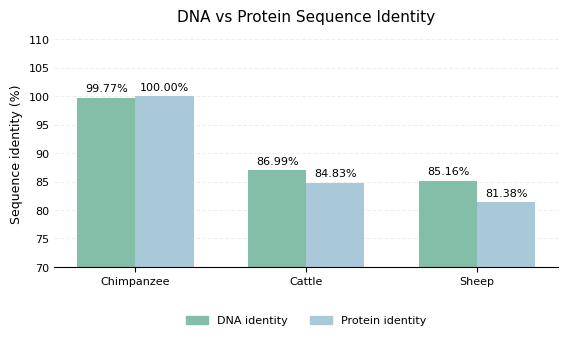

DNA AND PROTEIN IDENTITY COMPARISON
Chimpanzee   | DNA: 99.77% | Protein: 100.00%
Cattle       | DNA: 86.99% | Protein: 84.83%
Sheep        | DNA: 85.16% | Protein: 81.38%


In [323]:
import matplotlib.pyplot as plt
import numpy as np

# Calculate DNA identity relative to human
dna_records = list(alignment)

human_dna = next(
    record for record in dna_records
    if record.id == hbb_dataset["Human"]["accession"]
)

dna_identity = {}

for record in dna_records:
    species_name = next(
        species for species, data in hbb_dataset.items()
        if data["accession"] == record.id
    )

    sequence1 = str(human_dna.seq).upper()
    sequence2 = str(record.seq).upper()

    comparable = [
        (a, b)
        for a, b in zip(sequence1, sequence2)
        if a != "-" and b != "-"
    ]

    matches = sum(a == b for a, b in comparable)

    dna_identity[species_name] = (
        matches / len(comparable) * 100
    )

# Calculate protein identity relative to human
protein_records = list(protein_alignment)

human_protein = next(
    record for record in protein_records
    if record.id == "Human"
)

protein_identity = {}

for record in protein_records:
    sequence1 = str(human_protein.seq).upper()
    sequence2 = str(record.seq).upper()

    comparable = [
        (a, b)
        for a, b in zip(sequence1, sequence2)
        if a != "-" and b != "-"
    ]

    matches = sum(a == b for a, b in comparable)

    protein_identity[record.id] = (
        matches / len(comparable) * 100
    )

# Prepare comparison
species = ["Chimpanzee", "Cattle", "Sheep"]

dna_values = [dna_identity[name] for name in species]
protein_values = [protein_identity[name] for name in species]

x = np.arange(len(species))
width = 0.34

# Create visualization
fig, ax = plt.subplots(figsize=(6.5, 3.5))

dna_bars = ax.bar(
    x - width / 2,
    dna_values,
    width,
    color="#83BFA8"
)

protein_bars = ax.bar(
    x + width / 2,
    protein_values,
    width,
    color="#A9C9D9"
)

ax.bar_label(
    dna_bars,
    labels=[f"{v:.2f}%" for v in dna_values],
    padding=3,
    fontsize=8
)

ax.bar_label(
    protein_bars,
    labels=[f"{v:.2f}%" for v in protein_values],
    padding=3,
    fontsize=8
)

ax.set_title(
    "DNA vs Protein Sequence Identity",
    fontsize=11,
    pad=13
)

ax.set_ylabel("Sequence identity (%)", fontsize=9)
ax.set_xticks(x)
ax.set_xticklabels(species, fontsize=8)
ax.set_ylim(70, 110)

ax.tick_params(axis="y", labelsize=8, length=0)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.spines["left"].set_visible(False)

ax.grid(axis="y", linestyle="--", alpha=0.2)
ax.set_axisbelow(True)

ax.legend(
    handles=[
        plt.Rectangle((0, 0), 1, 1, color="#83BFA8", label="DNA identity"),
        plt.Rectangle((0, 0), 1, 1, color="#A9C9D9", label="Protein identity")
    ],
    loc="upper center",
    bbox_to_anchor=(0.5, -0.17),
    ncol=2,
    frameon=False,
    fontsize=8
)

plt.subplots_adjust(bottom=0.23)
plt.show()

# Display numerical results
print("DNA AND PROTEIN IDENTITY COMPARISON")
print("=" * 60)

for name in species:
    print(
        f"{name:12} | "
        f"DNA: {dna_identity[name]:.2f}% | "
        f"Protein: {protein_identity[name]:.2f}%"
    )

In [324]:
# Identify continuous conserved amino acid regions

conserved_regions = []
current_region = []

for position in range(protein_alignment.get_alignment_length()):

    amino_acids = [
        str(record.seq[position]).upper()
        for record in protein_alignment
    ]

    if "-" not in amino_acids and len(set(amino_acids)) == 1:
        current_region.append((position + 1, amino_acids[0]))

    else:
        if len(current_region) >= 3:
            conserved_regions.append(current_region)

        current_region = []

# Capture the final region if it reaches the minimum length
if len(current_region) >= 3:
    conserved_regions.append(current_region)

print("CONSERVED HBB PROTEIN REGIONS")
print("=" * 65)

if conserved_regions:
    for index, region in enumerate(conserved_regions, start=1):
        start = region[0][0]
        end = region[-1][0]
        sequence = "".join(aa for _, aa in region)

        print(f"\nRegion {index}")
        print(f"Alignment positions: {start}-{end}")
        print(f"Length: {len(region)} amino acids")
        print(f"Conserved sequence: {sequence}")

    total_conserved_region_length = sum(
        len(region) for region in conserved_regions
    )

    print("\nSUMMARY")
    print("-" * 65)
    print(f"Number of conserved regions: {len(conserved_regions)}")
    print(
        f"Total amino acids in conserved regions: "
        f"{total_conserved_region_length}"
    )

else:
    print("No conserved regions of at least 3 consecutive amino acids found.")


CONSERVED HBB PROTEIN REGIONS

Region 1
Alignment positions: 7-9
Length: 3 amino acids
Conserved sequence: EEK

Region 2
Alignment positions: 11-13
Length: 3 amino acids
Conserved sequence: AVT

Region 3
Alignment positions: 16-19
Length: 4 amino acids
Conserved sequence: WGKV

Region 4
Alignment positions: 21-25
Length: 5 amino acids
Conserved sequence: VDEVG

Region 5
Alignment positions: 27-44
Length: 18 amino acids
Conserved sequence: EALGRLLVVYPWTQRFFE

Region 6
Alignment positions: 46-50
Length: 5 amino acids
Conserved sequence: FGDLS

Region 7
Alignment positions: 53-56
Length: 4 amino acids
Conserved sequence: DAVM

Region 8
Alignment positions: 60-69
Length: 10 amino acids
Conserved sequence: KVKAHGKKVL

Region 9
Alignment positions: 78-80
Length: 3 amino acids
Conserved sequence: HLD

Region 10
Alignment positions: 82-87
Length: 6 amino acids
Conserved sequence: LKGTFA

Region 11
Alignment positions: 89-104
Length: 16 amino acids
Conserved sequence: LSELHCDKLHVDPENF

Region 1

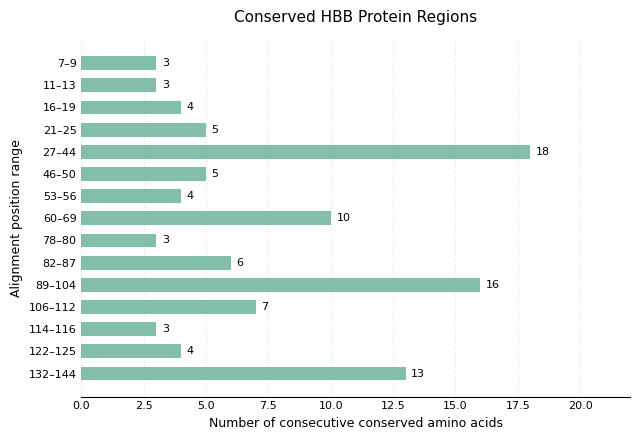

CONSERVED REGION SUMMARY
Number of regions: 15
Total conserved amino acids in these regions: 104
Longest region: 18 amino acids
Shortest region: 3 amino acids


In [325]:
import matplotlib.pyplot as plt
import numpy as np

region_labels = [
    f"{region[0][0]}–{region[-1][0]}"
    for region in conserved_regions
]

region_lengths = [
    len(region)
    for region in conserved_regions
]

fig, ax = plt.subplots(figsize=(6.5, 4.5))

y = np.arange(len(conserved_regions))

bars = ax.barh(
    y,
    region_lengths,
    color="#83BFA8",
    height=0.62
)

ax.set_yticks(y)
ax.set_yticklabels(region_labels, fontsize=8)
ax.invert_yaxis()

ax.bar_label(
    bars,
    labels=[str(length) for length in region_lengths],
    padding=4,
    fontsize=8
)

ax.set_title(
    "Conserved HBB Protein Regions",
    fontsize=11,
    pad=13
)

ax.set_xlabel("Number of consecutive conserved amino acids", fontsize=9)
ax.set_ylabel("Alignment position range", fontsize=9)
ax.set_xlim(0, max(region_lengths) + 4)

ax.tick_params(axis="x", labelsize=8, length=0)
ax.tick_params(axis="y", length=0)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.spines["left"].set_visible(False)

ax.grid(axis="x", linestyle="--", alpha=0.2)
ax.set_axisbelow(True)

plt.tight_layout()
plt.show()

print("CONSERVED REGION SUMMARY")
print("=" * 45)
print(f"Number of regions: {len(conserved_regions)}")
print(f"Total conserved amino acids in these regions: {sum(region_lengths)}")
print(f"Longest region: {max(region_lengths)} amino acids")
print(f"Shortest region: {min(region_lengths)} amino acids")

GC CONTENT BY CODON POSITION

Human
First position:  66.22%
Second position: 36.49%
Third position:  65.54%

Chimpanzee
First position:  66.22%
Second position: 36.49%
Third position:  66.22%

Cattle
First position:  63.01%
Second position: 33.56%
Third position:  65.07%

Sheep
First position:  66.44%
Second position: 33.56%
Third position:  67.81%


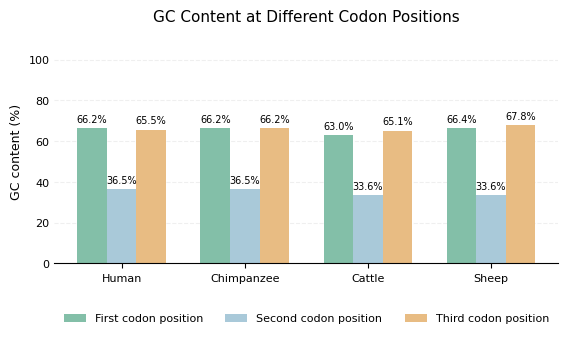

In [326]:
import matplotlib.pyplot as plt
import numpy as np

species = list(hbb_dataset.keys())

codon_positions = {
    "First": [],
    "Second": [],
    "Third": []
}

for species_name, data in hbb_dataset.items():
    sequence = data["sequence"].upper()

    for index, position_name in enumerate(codon_positions):
        nucleotides = sequence[index::3]

        gc_percentage = (
            (nucleotides.count("G") + nucleotides.count("C"))
            / len(nucleotides)
        ) * 100

        codon_positions[position_name].append(gc_percentage)

# Display numerical results
print("GC CONTENT BY CODON POSITION")
print("=" * 65)

for i, species_name in enumerate(species):
    print(f"\n{species_name}")
    print(f"First position:  {codon_positions['First'][i]:.2f}%")
    print(f"Second position: {codon_positions['Second'][i]:.2f}%")
    print(f"Third position:  {codon_positions['Third'][i]:.2f}%")

# Create comparison chart
x = np.arange(len(species))
width = 0.24

fig, ax = plt.subplots(figsize=(6.5, 3.5))

colors = ["#83BFA8", "#A9C9D9", "#E8BC83"]

for i, (position_name, values) in enumerate(codon_positions.items()):
    bars = ax.bar(
        x + (i - 1) * width,
        values,
        width,
        color=colors[i],
        label=f"{position_name} codon position"
    )

    ax.bar_label(
        bars,
        labels=[f"{value:.1f}%" for value in values],
        padding=3,
        fontsize=7
    )

ax.set_title(
    "GC Content at Different Codon Positions",
    fontsize=11,
    pad=13
)

ax.set_ylabel("GC content (%)", fontsize=9)
ax.set_xticks(x)
ax.set_xticklabels(species, fontsize=8)
ax.set_ylim(0, 110)

ax.tick_params(axis="y", labelsize=8, length=0)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.spines["left"].set_visible(False)

ax.grid(axis="y", linestyle="--", alpha=0.2)
ax.set_axisbelow(True)

ax.legend(
    loc="upper center",
    bbox_to_anchor=(0.5, -0.18),
    ncol=3,
    frameon=False,
    fontsize=8
)

plt.subplots_adjust(bottom=0.24)
plt.show()

GC CONTENT BY CODON POSITION (STOP CODON EXCLUDED)

Human
First position:  66.67%
Second position: 36.73%
Third position:  65.99%

Chimpanzee
First position:  66.67%
Second position: 36.73%
Third position:  66.67%

Cattle
First position:  63.45%
Second position: 33.79%
Third position:  65.52%

Sheep
First position:  66.90%
Second position: 33.79%
Third position:  68.28%


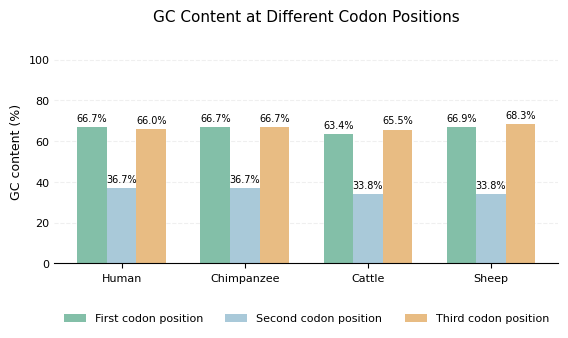

In [327]:

import matplotlib.pyplot as plt
import numpy as np

species = list(hbb_dataset.keys())

codon_positions = {
    "First": [],
    "Second": [],
    "Third": []
}

for species_name, data in hbb_dataset.items():
    sequence = data["sequence"].upper()[:-3]  # Exclude stop codon

    for index, position_name in enumerate(codon_positions):
        nucleotides = sequence[index::3]

        gc_percentage = (
            (nucleotides.count("G") + nucleotides.count("C"))
            / len(nucleotides)
        ) * 100

        codon_positions[position_name].append(gc_percentage)

print("GC CONTENT BY CODON POSITION (STOP CODON EXCLUDED)")
print("=" * 65)

for i, species_name in enumerate(species):
    print(f"\n{species_name}")
    print(f"First position:  {codon_positions['First'][i]:.2f}%")
    print(f"Second position: {codon_positions['Second'][i]:.2f}%")
    print(f"Third position:  {codon_positions['Third'][i]:.2f}%")

x = np.arange(len(species))
width = 0.24

fig, ax = plt.subplots(figsize=(6.5, 3.5))
colors = ["#83BFA8", "#A9C9D9", "#E8BC83"]

for i, (position_name, values) in enumerate(codon_positions.items()):
    bars = ax.bar(
        x + (i - 1) * width,
        values,
        width,
        color=colors[i],
        label=f"{position_name} codon position"
    )

    ax.bar_label(
        bars,
        labels=[f"{value:.1f}%" for value in values],
        padding=3,
        fontsize=7
    )

ax.set_title("GC Content at Different Codon Positions",
             fontsize=11, pad=13)
ax.set_ylabel("GC content (%)", fontsize=9)
ax.set_xticks(x)
ax.set_xticklabels(species, fontsize=8)
ax.set_ylim(0, 110)

ax.tick_params(axis="y", labelsize=8, length=0)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.spines["left"].set_visible(False)

ax.grid(axis="y", linestyle="--", alpha=0.2)
ax.set_axisbelow(True)

ax.legend(
    loc="upper center",
    bbox_to_anchor=(0.5, -0.18),
    ncol=3,
    frameon=False,
    fontsize=8
)

plt.subplots_adjust(bottom=0.24)
plt.show()


TOP 12 CODONS — FREQUENCY PER 1,000 CODONS
Codon       Human          Chimpanzee     Cattle         Sheep          
CTG         101.35         101.35         75.34          82.19          
GTG         87.84          87.84          82.19          82.19          
AAG         54.05          54.05          82.19          61.64          
GCC         60.81          60.81          47.95          41.10          
GGC         54.05          54.05          47.95          54.79          
GCT         40.54          40.54          54.79          68.49          
GAG         40.54          40.54          41.10          41.10          
TTT         33.78          33.78          47.95          34.25          
CAC         40.54          47.30          13.70          41.10          
GAT         33.78          33.78          41.10          27.40          
AAC         33.78          33.78          27.40          34.25          
GTT         20.27          20.27          27.40          34.25          


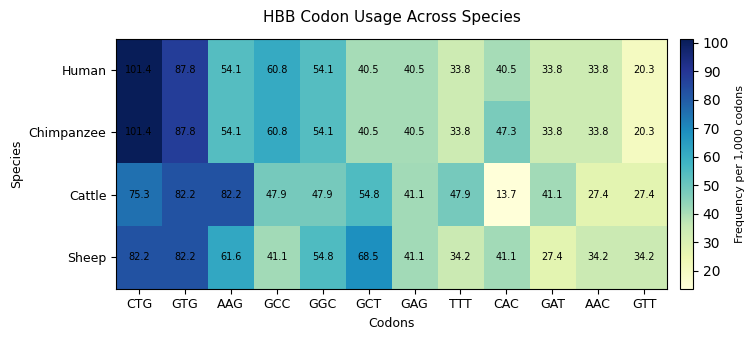

In [328]:
from collections import Counter
import numpy as np
import matplotlib.pyplot as plt

codon_counts = {}
codon_frequencies = {}

for species_name, data in hbb_dataset.items():
    sequence = data["sequence"].upper()

    codons = [
        sequence[i:i+3]
        for i in range(0, len(sequence), 3)
    ]

    counts = Counter(codons)
    total_codons = len(codons)

    codon_counts[species_name] = counts

    codon_frequencies[species_name] = {
        codon: (count / total_codons) * 1000
        for codon, count in counts.items()
    }

# Identify the 12 most frequent codons across all species
combined_counts = Counter()

for counts in codon_counts.values():
    combined_counts.update(counts)

top_codons = [
    str(codon) for codon, count in combined_counts.most_common(12)
]

# Create frequency matrix
frequency_matrix = np.array([
    [
        codon_frequencies[species].get(codon, 0)
        for codon in top_codons
    ]
    for species in hbb_dataset
])

# Display numerical results
print("TOP 12 CODONS — FREQUENCY PER 1,000 CODONS")
print("=" * 65)

print(f"{'Codon':<12}", end="")
for species in hbb_dataset:
    print(f"{species:<15}", end="")
print()

for i, codon in enumerate(top_codons):
    print(f"{codon:<12}", end="")
    for j in range(len(hbb_dataset)):
        print(f"{frequency_matrix[j, i]:<15.2f}", end="")
    print()

# Visualize codon usage
fig, ax = plt.subplots(figsize=(8, 3.5))

image = ax.imshow(
    frequency_matrix,
    cmap="YlGnBu",
    aspect="auto"
)

ax.set_xticks(range(len(top_codons)))
ax.set_xticklabels(top_codons, fontsize=9)

ax.set_yticks(range(len(hbb_dataset)))
ax.set_yticklabels(list(hbb_dataset.keys()), fontsize=9)

ax.set_title(
    "HBB Codon Usage Across Species",
    fontsize=11,
    pad=12
)

ax.set_xlabel("Codons", fontsize=9)
ax.set_ylabel("Species", fontsize=9)

for i in range(len(hbb_dataset)):
    for j in range(len(top_codons)):
        ax.text(
            j, i,
            f"{frequency_matrix[i, j]:.1f}",
            ha="center",
            va="center",
            fontsize=7,
            color="black"
        )

colorbar = plt.colorbar(image, ax=ax, pad=0.02)
colorbar.set_label("Frequency per 1,000 codons", fontsize=8)

plt.tight_layout()
plt.show()

HBB PROTEIN VARIABILITY BY REGION
Region         Variable sites    Variability    
1–10           2/8               25.00%
11–20          3/10              30.00%
21–30          1/10              10.00%
31–40          0/10              0.00%
41–50          1/10              10.00%
51–60          4/10              40.00%
61–70          1/10              10.00%
71–80          4/10              40.00%
81–90          2/10              20.00%
91–100         0/10              0.00%
101–110        1/10              10.00%
111–120        4/10              40.00%
121–130        4/10              40.00%
131–140        1/10              10.00%
141–147        1/7               14.29%

KEY FINDING
Most variable region: 51–60
Variability: 40.00%


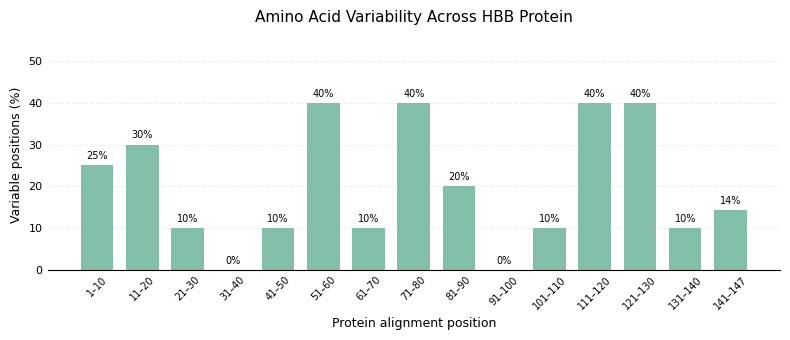

In [329]:
import numpy as np
import matplotlib.pyplot as plt

window_size = 10
alignment_length = protein_alignment.get_alignment_length()

window_labels = []
variability_percentages = []
variable_counts = []
comparable_counts = []

for start in range(0, alignment_length, window_size):
    end = min(start + window_size, alignment_length)

    variable = 0
    comparable = 0

    for position in range(start, end):
        amino_acids = [
            str(record.seq[position])
            for record in protein_alignment
        ]

        if "-" in amino_acids:
            continue

        comparable += 1

        if len(set(amino_acids)) > 1:
            variable += 1

    if comparable > 0:
        percentage = (variable / comparable) * 100
    else:
        percentage = 0

    window_labels.append(f"{start + 1}–{end}")
    variability_percentages.append(percentage)
    variable_counts.append(variable)
    comparable_counts.append(comparable)

# Display numerical results
print("HBB PROTEIN VARIABILITY BY REGION")
print("=" * 55)
print(f"{'Region':<15}{'Variable sites':<18}{'Variability':<15}")

for label, variable, comparable, percentage in zip(
    window_labels,
    variable_counts,
    comparable_counts,
    variability_percentages
):
    print(
        f"{label:<15}{variable}/{comparable:<16}{percentage:.2f}%"
    )

# Identify the most variable region
highest_index = np.argmax(variability_percentages)

print("\nKEY FINDING")
print("=" * 55)
print(
    f"Most variable region: {window_labels[highest_index]}"
)
print(
    f"Variability: {variability_percentages[highest_index]:.2f}%"
)

# Plot variability across the protein
fig, ax = plt.subplots(figsize=(8, 3.5))

bars = ax.bar(
    window_labels,
    variability_percentages,
    color="#83BFA8",
    width=0.72
)

ax.bar_label(
    bars,
    labels=[f"{value:.0f}%" for value in variability_percentages],
    padding=3,
    fontsize=7
)

ax.set_title(
    "Amino Acid Variability Across HBB Protein",
    fontsize=11,
    pad=13
)

ax.set_xlabel("Protein alignment position", fontsize=9)
ax.set_ylabel("Variable positions (%)", fontsize=9)

ax.set_ylim(
    0,
    max(variability_percentages) + 15
)

ax.tick_params(axis="x", labelsize=7, rotation=45, length=0)
ax.tick_params(axis="y", labelsize=8, length=0)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.spines["left"].set_visible(False)

ax.grid(axis="y", linestyle="--", alpha=0.2)
ax.set_axisbelow(True)

plt.tight_layout()
plt.show()

CONSERVED HBB AMINO ACID POSITIONS
Position   1: M
Position   4: L
Position   5: T
Position   7: E
Position   8: E
Position   9: K
Position  11: A
Position  12: V
Position  13: T
Position  16: W
Position  17: G
Position  18: K
Position  19: V
Position  21: V
Position  22: D
Position  23: E
Position  24: V
Position  25: G
Position  27: E
Position  28: A
Position  29: L
Position  30: G
Position  31: R
Position  32: L
Position  33: L
Position  34: V
Position  35: V
Position  36: Y
Position  37: P
Position  38: W
Position  39: T
Position  40: Q
Position  41: R
Position  42: F
Position  43: F
Position  44: E
Position  46: F
Position  47: G
Position  48: D
Position  49: L
Position  50: S
Position  53: D
Position  54: A
Position  55: V
Position  56: M
Position  58: N
Position  60: K
Position  61: V
Position  62: K
Position  63: A
Position  64: H
Position  65: G
Position  66: K
Position  67: K
Position  68: V
Position  69: L
Position  72: F
Position  73: S
Position  75: G
Position  78: H
Posit

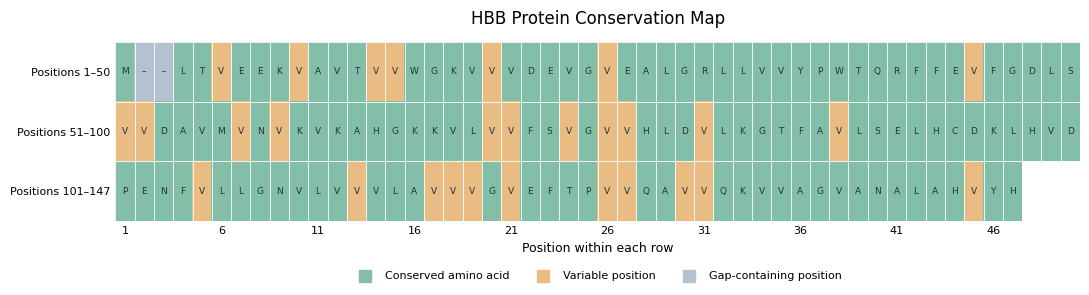

In [330]:
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap, BoundaryNorm
import numpy as np

# Identify conserved amino acid positions
conserved_positions = []

for position in range(protein_alignment.get_alignment_length()):
    amino_acids = [
        str(record.seq[position])
        for record in protein_alignment
    ]

    if "-" not in amino_acids and len(set(amino_acids)) == 1:
        conserved_positions.append({
            "Position": position + 1,
            "Amino acid": amino_acids[0]
        })

# Display conserved positions
print("CONSERVED HBB AMINO ACID POSITIONS")
print("=" * 55)

for item in conserved_positions:
    print(
        f"Position {item['Position']:>3}: "
        f"{item['Amino acid']}"
    )

# Calculate conservation statistics
alignment_length = protein_alignment.get_alignment_length()

gap_positions = sum(
    "-" in [str(record.seq[position]) for record in protein_alignment]
    for position in range(alignment_length)
)

comparable_positions = alignment_length - gap_positions
variable_positions = comparable_positions - len(conserved_positions)

conservation_percentage = (
    len(conserved_positions) / comparable_positions
) * 100

print("\nCONSERVATION SUMMARY")
print("=" * 55)
print(f"Total alignment positions: {alignment_length}")
print(f"Conserved positions: {len(conserved_positions)}")
print(f"Variable positions: {variable_positions}")
print(f"Gap-containing positions: {gap_positions}")
print(f"Comparable positions: {comparable_positions}")
print(f"Conservation percentage: {conservation_percentage:.2f}%")

# Prepare conservation map
positions_per_row = 50
number_of_rows = int(np.ceil(alignment_length / positions_per_row))

status_matrix = np.full(
    (number_of_rows, positions_per_row),
    np.nan
)

label_matrix = np.full(
    (number_of_rows, positions_per_row),
    "",
    dtype=object
)

for position in range(alignment_length):
    row = position // positions_per_row
    column = position % positions_per_row

    amino_acids = [
        str(record.seq[position])
        for record in protein_alignment
    ]

    if "-" in amino_acids:
        status_matrix[row, column] = 2
        label_matrix[row, column] = "–"

    elif len(set(amino_acids)) == 1:
        status_matrix[row, column] = 0
        label_matrix[row, column] = amino_acids[0]

    else:
        status_matrix[row, column] = 1
        label_matrix[row, column] = "V"

# Create conservation map
colors = ["#83BFA8", "#E8BC83", "#B5C1D0"]

cmap = ListedColormap(colors)
norm = BoundaryNorm(
    [-0.5, 0.5, 1.5, 2.5],
    cmap.N
)

fig, ax = plt.subplots(figsize=(11, 3.2))

ax.imshow(
    status_matrix,
    cmap=cmap,
    norm=norm,
    aspect="auto"
)

# Add amino acid and variability labels
for row in range(number_of_rows):
    for column in range(positions_per_row):
        label = label_matrix[row, column]

        if label:
            ax.text(
                column,
                row,
                label,
                ha="center",
                va="center",
                fontsize=6.5,
                color="#263238"
            )

# Configure axes
row_labels = []

for row in range(number_of_rows):
    start = row * positions_per_row + 1
    end = min((row + 1) * positions_per_row, alignment_length)
    row_labels.append(f"Positions {start}–{end}")

ax.set_yticks(range(number_of_rows))
ax.set_yticklabels(row_labels, fontsize=8)

ax.set_xticks(range(0, positions_per_row, 5))
ax.set_xticklabels(
    [str(i + 1) for i in range(0, positions_per_row, 5)],
    fontsize=8
)

ax.set_xlabel("Position within each row", fontsize=9)

ax.set_title(
    "HBB Protein Conservation Map",
    fontsize=12,
    pad=13
)

ax.tick_params(axis="both", length=0)

ax.set_xticks(
    np.arange(-0.5, positions_per_row, 1),
    minor=True
)

ax.set_yticks(
    np.arange(-0.5, number_of_rows, 1),
    minor=True
)

ax.grid(
    which="minor",
    color="white",
    linestyle="-",
    linewidth=0.6
)

ax.tick_params(which="minor", bottom=False, left=False)

for spine in ax.spines.values():
    spine.set_visible(False)

# Add legend
legend_labels = [
    ("#83BFA8", "Conserved amino acid"),
    ("#E8BC83", "Variable position"),
    ("#B5C1D0", "Gap-containing position")
]

for color, label in legend_labels:
    ax.scatter(
        [],
        [],
        color=color,
        marker="s",
        s=65,
        label=label
    )

ax.legend(
    loc="upper center",
    bbox_to_anchor=(0.5, -0.22),
    ncol=3,
    frameon=False,
    fontsize=8
)

plt.tight_layout()
plt.show()

HBB AMINO ACID COMPOSITION

Human
----------------------------------------
A:  15 (10.20%)
C:   2 (1.36%)
D:   7 (4.76%)
E:   8 (5.44%)
F:   8 (5.44%)
G:  13 (8.84%)
H:   9 (6.12%)
K:  11 (7.48%)
L:  18 (12.24%)
M:   2 (1.36%)
N:   6 (4.08%)
P:   7 (4.76%)
Q:   3 (2.04%)
R:   3 (2.04%)
S:   5 (3.40%)
T:   7 (4.76%)
V:  18 (12.24%)
W:   2 (1.36%)
Y:   3 (2.04%)
Most abundant amino acid: V (18 occurrences)

Chimpanzee
----------------------------------------
A:  15 (10.20%)
C:   2 (1.36%)
D:   7 (4.76%)
E:   8 (5.44%)
F:   8 (5.44%)
G:  13 (8.84%)
H:   9 (6.12%)
K:  11 (7.48%)
L:  18 (12.24%)
M:   2 (1.36%)
N:   6 (4.08%)
P:   7 (4.76%)
Q:   3 (2.04%)
R:   3 (2.04%)
S:   5 (3.40%)
T:   7 (4.76%)
V:  18 (12.24%)
W:   2 (1.36%)
Y:   3 (2.04%)
Most abundant amino acid: V (18 occurrences)

Cattle
----------------------------------------
A:  16 (11.03%)
C:   1 (0.69%)
D:   9 (6.21%)
E:   8 (5.52%)
F:  10 (6.90%)
G:  11 (7.59%)
H:   6 (4.14%)
K:  13 (8.97%)
L:  17 (11.72%)
M:   3 (2.07%)
N:   

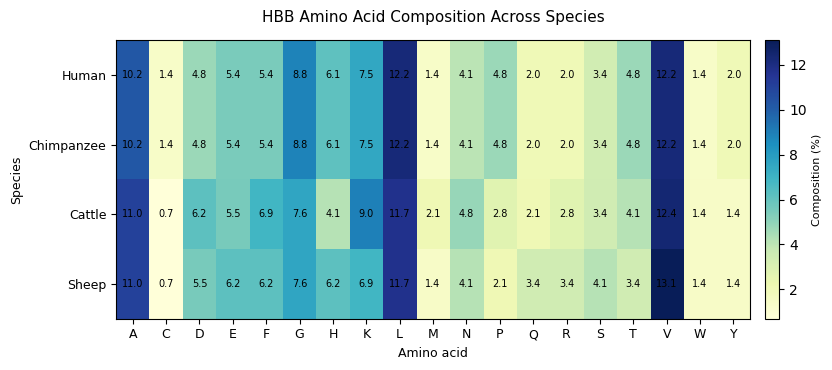

In [331]:
from collections import Counter
import numpy as np
import matplotlib.pyplot as plt

amino_acid_counts = {}
amino_acid_percentages = {}

for species_name, data in hbb_dataset.items():
    protein = str(Seq(data["sequence"]).translate()).rstrip("*")

    counts = Counter(protein)
    total_amino_acids = len(protein)

    amino_acid_counts[species_name] = counts

    amino_acid_percentages[species_name] = {
        amino_acid: (count / total_amino_acids) * 100
        for amino_acid, count in counts.items()
    }

# Identify amino acids found across the dataset
all_amino_acids = sorted(
    set().union(
        *[set(counts.keys()) for counts in amino_acid_counts.values()]
    )
)

# Display numerical results
print("HBB AMINO ACID COMPOSITION")
print("=" * 65)

for species_name in hbb_dataset:
    print(f"\n{species_name}")
    print("-" * 40)

    for amino_acid in all_amino_acids:
        count = amino_acid_counts[species_name].get(amino_acid, 0)
        percentage = amino_acid_percentages[species_name].get(
            amino_acid, 0
        )

        print(
            f"{amino_acid}: {count:>3} "
            f"({percentage:.2f}%)"
        )

    most_common = amino_acid_counts[species_name].most_common(1)[0]

    print(
        f"Most abundant amino acid: "
        f"{most_common[0]} ({most_common[1]} occurrences)"
    )

# Prepare composition matrix
composition_matrix = np.array([
    [
        amino_acid_percentages[species].get(amino_acid, 0)
        for amino_acid in all_amino_acids
    ]
    for species in hbb_dataset
])

# Create heatmap
fig, ax = plt.subplots(figsize=(9, 3.8))

image = ax.imshow(
    composition_matrix,
    cmap="YlGnBu",
    aspect="auto"
)

ax.set_xticks(range(len(all_amino_acids)))
ax.set_xticklabels(all_amino_acids, fontsize=9)

ax.set_yticks(range(len(hbb_dataset)))
ax.set_yticklabels(list(hbb_dataset.keys()), fontsize=9)

ax.set_title(
    "HBB Amino Acid Composition Across Species",
    fontsize=11,
    pad=13
)

ax.set_xlabel("Amino acid", fontsize=9)
ax.set_ylabel("Species", fontsize=9)

for i in range(len(hbb_dataset)):
    for j in range(len(all_amino_acids)):
        ax.text(
            j,
            i,
            f"{composition_matrix[i, j]:.1f}",
            ha="center",
            va="center",
            fontsize=7,
            color="black"
        )

colorbar = plt.colorbar(image, ax=ax, pad=0.02)
colorbar.set_label("Composition (%)", fontsize=8)

plt.tight_layout()
plt.show()

HBB AMINO ACID PROPERTY COMPOSITION

Human
---------------------------------------------
Nonpolar aliphatic       53 (36.05%)
Aromatic                 13 (8.84%)
Polar uncharged          21 (14.29%)
Positive                 23 (15.65%)
Negative                 15 (10.20%)
Special structural       22 (14.97%)

Chimpanzee
---------------------------------------------
Nonpolar aliphatic       53 (36.05%)
Aromatic                 13 (8.84%)
Polar uncharged          21 (14.29%)
Positive                 23 (15.65%)
Negative                 15 (10.20%)
Special structural       22 (14.97%)

Cattle
---------------------------------------------
Nonpolar aliphatic       54 (37.24%)
Aromatic                 14 (9.66%)
Polar uncharged          21 (14.48%)
Positive                 23 (15.86%)
Negative                 17 (11.72%)
Special structural       16 (11.03%)

Sheep
---------------------------------------------
Nonpolar aliphatic       54 (37.24%)
Aromatic                 13 (8.97%)
Polar unch

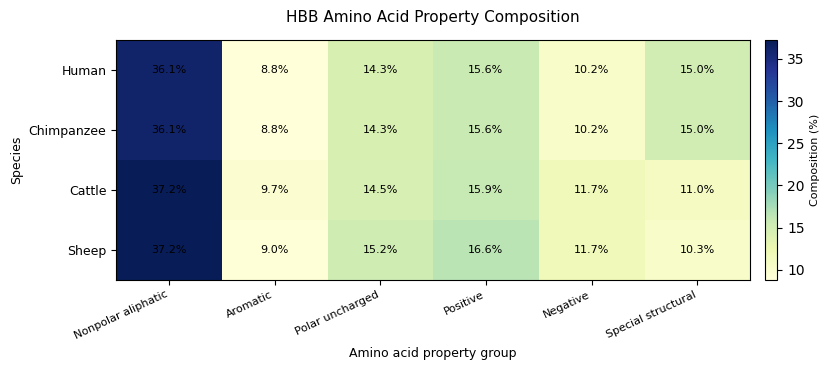

In [332]:
import numpy as np
import matplotlib.pyplot as plt

amino_acid_groups = {
    "Nonpolar aliphatic": set("AVILM"),
    "Aromatic": set("FWY"),
    "Polar uncharged": set("STNQ"),
    "Positive": set("KRH"),
    "Negative": set("DE"),
    "Special structural": set("GPC")
}

group_percentages = {}
group_counts = {}

for species_name, data in hbb_dataset.items():

    protein = str(Seq(data["sequence"]).translate()).rstrip("*")

    total = len(protein)

    group_counts[species_name] = {}
    group_percentages[species_name] = {}

    for group_name, amino_acids in amino_acid_groups.items():

        count = sum(
            1 for aa in protein if aa in amino_acids
        )

        percentage = (count / total) * 100

        group_counts[species_name][group_name] = count
        group_percentages[species_name][group_name] = percentage

# Display results
print("HBB AMINO ACID PROPERTY COMPOSITION")
print("=" * 65)

for species_name in hbb_dataset:

    print(f"\n{species_name}")
    print("-" * 45)

    for group_name in amino_acid_groups:

        count = group_counts[species_name][group_name]
        percentage = group_percentages[species_name][group_name]

        print(
            f"{group_name:<23} {count:>3} "
            f"({percentage:.2f}%)"
        )

# Prepare visualization
species = list(hbb_dataset.keys())
groups = list(amino_acid_groups.keys())

composition_matrix = np.array([
    [
        group_percentages[species_name][group]
        for group in groups
    ]
    for species_name in species
])

# Create heatmap
fig, ax = plt.subplots(figsize=(9, 3.8))

image = ax.imshow(
    composition_matrix,
    cmap="YlGnBu",
    aspect="auto"
)

ax.set_xticks(range(len(groups)))
ax.set_xticklabels(groups, rotation=25, ha="right", fontsize=8)

ax.set_yticks(range(len(species)))
ax.set_yticklabels(species, fontsize=9)

ax.set_title(
    "HBB Amino Acid Property Composition",
    fontsize=11,
    pad=13
)

ax.set_xlabel("Amino acid property group", fontsize=9)
ax.set_ylabel("Species", fontsize=9)

for i in range(len(species)):
    for j in range(len(groups)):

        ax.text(
            j,
            i,
            f"{composition_matrix[i, j]:.1f}%",
            ha="center",
            va="center",
            fontsize=8,
            color="black"
        )

colorbar = plt.colorbar(image, ax=ax, pad=0.02)
colorbar.set_label("Composition (%)", fontsize=8)

plt.tight_layout()
plt.show()

HBB PROTEIN MOLECULAR WEIGHT
Human           15,998.21 Da (16.00 kDa)
Chimpanzee      15,998.21 Da (16.00 kDa)
Cattle          15,954.19 Da (15.95 kDa)
Sheep           16,003.08 Da (16.00 kDa)


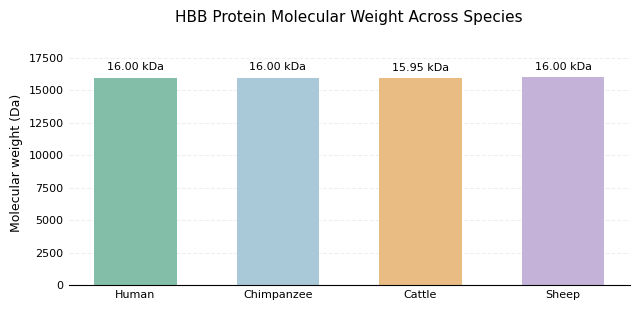

In [333]:
from Bio.SeqUtils.ProtParam import ProteinAnalysis
import matplotlib.pyplot as plt
import numpy as np

molecular_weights = {}

print("HBB PROTEIN MOLECULAR WEIGHT")
print("=" * 55)

for species_name, data in hbb_dataset.items():

    protein = str(Seq(data["sequence"]).translate()).rstrip("*")

    analysis = ProteinAnalysis(protein)
    molecular_weight = analysis.molecular_weight()

    molecular_weights[species_name] = molecular_weight

    print(
        f"{species_name:<15} "
        f"{molecular_weight:,.2f} Da "
        f"({molecular_weight / 1000:.2f} kDa)"
    )

# Create comparison chart
species = list(molecular_weights.keys())
weights = list(molecular_weights.values())

fig, ax = plt.subplots(figsize=(6.5, 3.2))

bars = ax.bar(
    species,
    weights,
    color=["#83BFA8", "#A9C9D9", "#E8BC83", "#C4B2D9"],
    width=0.58
)

ax.bar_label(
    bars,
    labels=[f"{weight / 1000:.2f} kDa" for weight in weights],
    padding=4,
    fontsize=8
)

ax.set_title(
    "HBB Protein Molecular Weight Across Species",
    fontsize=11,
    pad=13
)

ax.set_ylabel("Molecular weight (Da)", fontsize=9)
ax.set_ylim(0, max(weights) * 1.18)

ax.tick_params(axis="both", labelsize=8, length=0)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.spines["left"].set_visible(False)

ax.grid(axis="y", linestyle="--", alpha=0.2)
ax.set_axisbelow(True)

plt.tight_layout()
plt.show()

HBB THEORETICAL ISOELECTRIC POINT
Human           pI = 6.74
Chimpanzee      pI = 6.74
Cattle          pI = 7.02
Sheep           pI = 6.49


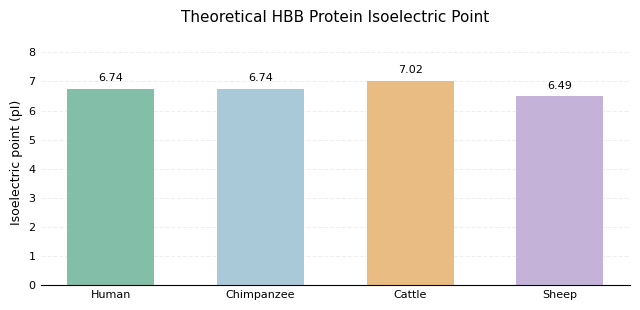

In [334]:
from Bio.SeqUtils.ProtParam import ProteinAnalysis
import matplotlib.pyplot as plt
import numpy as np

isoelectric_points = {}

print("HBB THEORETICAL ISOELECTRIC POINT")
print("=" * 55)

for species_name, data in hbb_dataset.items():

    protein = str(Seq(data["sequence"]).translate()).rstrip("*")

    analysis = ProteinAnalysis(protein)
    pi = analysis.isoelectric_point()

    isoelectric_points[species_name] = pi

    print(f"{species_name:<15} pI = {pi:.2f}")

# Prepare chart
species = list(isoelectric_points.keys())
values = list(isoelectric_points.values())

fig, ax = plt.subplots(figsize=(6.5, 3.2))

bars = ax.bar(
    species,
    values,
    color=["#83BFA8", "#A9C9D9", "#E8BC83", "#C4B2D9"],
    width=0.58
)

ax.bar_label(
    bars,
    labels=[f"{value:.2f}" for value in values],
    padding=4,
    fontsize=8
)

ax.set_title(
    "Theoretical HBB Protein Isoelectric Point",
    fontsize=11,
    pad=13
)

ax.set_ylabel("Isoelectric point (pI)", fontsize=9)
ax.set_ylim(0, max(values) * 1.2)

ax.tick_params(axis="both", labelsize=8, length=0)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.spines["left"].set_visible(False)

ax.grid(axis="y", linestyle="--", alpha=0.2)
ax.set_axisbelow(True)

plt.tight_layout()
plt.show()

HBB PROTEIN INSTABILITY INDEX
Human           6.16 — Stable (predicted)
Chimpanzee      6.16 — Stable (predicted)
Cattle          2.15 — Stable (predicted)
Sheep           5.05 — Stable (predicted)


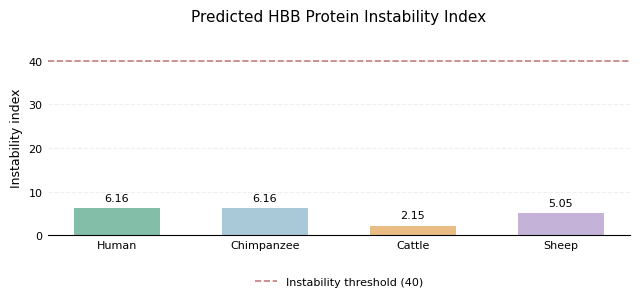

In [335]:
from Bio.SeqUtils.ProtParam import ProteinAnalysis
import matplotlib.pyplot as plt
import numpy as np

instability_indices = {}

print("HBB PROTEIN INSTABILITY INDEX")
print("=" * 55)

for species_name, data in hbb_dataset.items():

    protein = str(Seq(data["sequence"]).translate()).rstrip("*")

    analysis = ProteinAnalysis(protein)
    index = analysis.instability_index()

    instability_indices[species_name] = index

    classification = (
        "Stable (predicted)"
        if index < 40
        else "Unstable (predicted)"
    )

    print(
        f"{species_name:<15} "
        f"{index:.2f} — {classification}"
    )

# Create comparison chart
species = list(instability_indices.keys())
values = list(instability_indices.values())

fig, ax = plt.subplots(figsize=(6.5, 3.2))

bars = ax.bar(
    species,
    values,
    color=["#83BFA8", "#A9C9D9", "#E8BC83", "#C4B2D9"],
    width=0.58
)

ax.bar_label(
    bars,
    labels=[f"{value:.2f}" for value in values],
    padding=4,
    fontsize=8
)

ax.axhline(
    40,
    color="#C47D7D",
    linestyle="--",
    linewidth=1.2,
    label="Instability threshold (40)"
)

ax.set_title(
    "Predicted HBB Protein Instability Index",
    fontsize=11,
    pad=13
)

ax.set_ylabel("Instability index", fontsize=9)
ax.set_ylim(0, max(45, max(values) * 1.2))

ax.tick_params(axis="both", labelsize=8, length=0)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.spines["left"].set_visible(False)

ax.grid(axis="y", linestyle="--", alpha=0.2)
ax.set_axisbelow(True)

ax.legend(
    loc="upper center",
    bbox_to_anchor=(0.5, -0.16),
    frameon=False,
    fontsize=8
)

plt.tight_layout()
plt.show()

HBB PROTEIN ALIPHATIC INDEX
Human           93.47
Chimpanzee      93.47
Cattle          92.76
Sheep           94.76


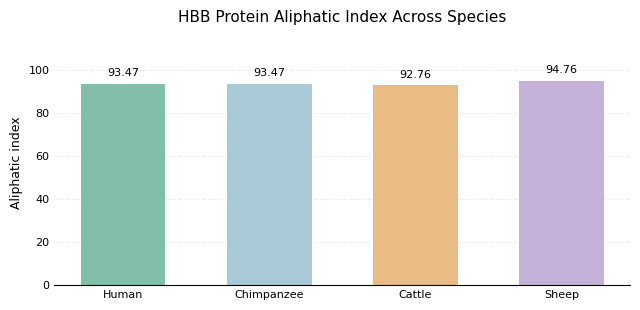

In [336]:
import matplotlib.pyplot as plt

aliphatic_indices = {}

print("HBB PROTEIN ALIPHATIC INDEX")
print("=" * 55)

for species_name, data in hbb_dataset.items():

    protein = str(Seq(data["sequence"]).translate()).rstrip("*")
    length = len(protein)

    # Calculate amino acid percentages
    alanine = protein.count("A") / length * 100
    valine = protein.count("V") / length * 100
    isoleucine = protein.count("I") / length * 100
    leucine = protein.count("L") / length * 100

    # Calculate aliphatic index
    index = (
        alanine
        + 2.9 * valine
        + 3.9 * (isoleucine + leucine)
    )

    aliphatic_indices[species_name] = index

    print(f"{species_name:<15} {index:.2f}")

# Create comparison chart
species = list(aliphatic_indices.keys())
values = list(aliphatic_indices.values())

fig, ax = plt.subplots(figsize=(6.5, 3.2))

bars = ax.bar(
    species,
    values,
    color=["#83BFA8", "#A9C9D9", "#E8BC83", "#C4B2D9"],
    width=0.58
)

ax.bar_label(
    bars,
    labels=[f"{value:.2f}" for value in values],
    padding=4,
    fontsize=8
)

ax.set_title(
    "HBB Protein Aliphatic Index Across Species",
    fontsize=11,
    pad=13
)

ax.set_ylabel("Aliphatic index", fontsize=9)
ax.set_ylim(0, max(values) * 1.2)

ax.tick_params(axis="both", labelsize=8, length=0)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.spines["left"].set_visible(False)

ax.grid(axis="y", linestyle="--", alpha=0.2)
ax.set_axisbelow(True)

plt.tight_layout()
plt.show()

HBB PROTEIN GRAVY SCORES
Human           0.0136 — Hydrophobic
Chimpanzee      0.0136 — Hydrophobic
Cattle          -0.0041 — Hydrophilic
Sheep           -0.0379 — Hydrophilic


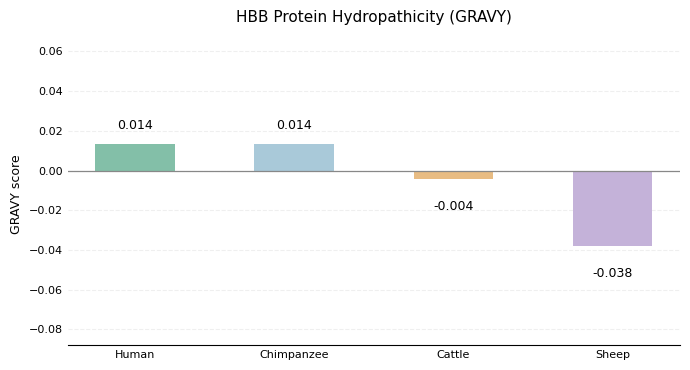

In [337]:

from Bio.SeqUtils.ProtParam import ProteinAnalysis
import matplotlib.pyplot as plt

# Calculate GRAVY scores
gravy_scores = {}

print("HBB PROTEIN GRAVY SCORES")
print("=" * 55)

for species_name, data in hbb_dataset.items():

    protein = str(Seq(data["sequence"]).translate()).rstrip("*")

    analysis = ProteinAnalysis(protein)
    gravy = analysis.gravy()

    gravy_scores[species_name] = gravy

    classification = (
        "Hydrophobic" if gravy > 0
        else "Hydrophilic" if gravy < 0
        else "Neutral"
    )

    print(
        f"{species_name:<15} "
        f"{gravy:.4f} — {classification}"
    )

# Create comparison chart
species = list(gravy_scores.keys())
values = list(gravy_scores.values())

fig, ax = plt.subplots(figsize=(7, 3.8))

bars = ax.bar(
    species,
    values,
    color=["#83BFA8", "#A9C9D9", "#E8BC83", "#C4B2D9"],
    width=0.5
)

# Add value labels without overlap
for bar, value in zip(bars, values):

    ax.annotate(
        f"{value:.3f}",
        xy=(bar.get_x() + bar.get_width() / 2, value),
        xytext=(0, 8 if value >= 0 else -15),
        textcoords="offset points",
        ha="center",
        va="bottom" if value >= 0 else "top",
        fontsize=9
    )

# Zero reference line
ax.axhline(
    0,
    color="#888888",
    linewidth=0.9
)

ax.set_title(
    "HBB Protein Hydropathicity (GRAVY)",
    fontsize=11,
    pad=16
)

ax.set_ylabel("GRAVY score", fontsize=9)

# Adjust chart limits to provide label space
lower = min(0, min(values))
upper = max(0, max(values))
padding = max((upper - lower) * 0.25, 0.05)

ax.set_ylim(
    lower - padding,
    upper + padding
)

ax.tick_params(
    axis="both",
    labelsize=8,
    length=0
)

# Minimalist styling
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.spines["left"].set_visible(False)

ax.grid(
    axis="y",
    linestyle="--",
    alpha=0.2
)

ax.set_axisbelow(True)

plt.tight_layout()
plt.show()


In [338]:

import pandas as pd

protein_properties = {}

for species_name, data in hbb_dataset.items():

    protein = str(Seq(data["sequence"]).translate()).rstrip("*")
    analysis = ProteinAnalysis(protein)

    protein_properties[species_name] = {
        "Molecular Weight (Da)": analysis.molecular_weight(),
        "Isoelectric Point (pI)": analysis.isoelectric_point(),
        "Instability Index": analysis.instability_index(),
        "Aliphatic Index": (
            protein.count("A") / len(protein) * 100
            + 2.9 * protein.count("V") / len(protein) * 100
            + 3.9 * (
                protein.count("I") / len(protein) * 100
                + protein.count("L") / len(protein) * 100
            )
        ),
        "GRAVY Score": analysis.gravy()
    }

# Create comparative table
protein_properties_df = pd.DataFrame(
    protein_properties
).T

protein_properties_df.index.name = "Species"

display(
    protein_properties_df.round(3)
)


,Molecular Weight (Da),Isoelectric Point (pI),Instability Index,Aliphatic Index,GRAVY Score
Species,,,,,
Human,15998.206,6.745,6.158,93.469,0.014
Chimpanzee,15998.206,6.745,6.158,93.469,0.014
Cattle,15954.192,7.017,2.146,92.759,-0.004
Sheep,16003.080,6.488,5.048,94.759,-0.038


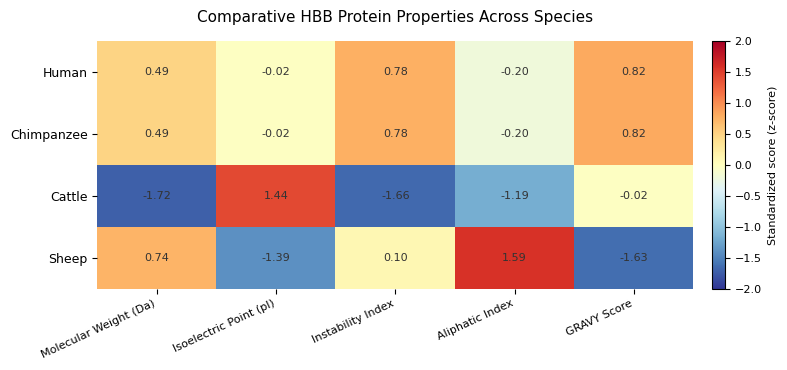

In [339]:

import numpy as np
import matplotlib.pyplot as plt

# Standardize each property using z-scores
standardized_properties = (
    protein_properties_df - protein_properties_df.mean()
) / protein_properties_df.std(ddof=0)

fig, ax = plt.subplots(figsize=(8, 3.8))

image = ax.imshow(
    standardized_properties.values,
    cmap="RdYlBu_r",
    aspect="auto",
    vmin=-2,
    vmax=2
)

# Add numerical labels
for i in range(standardized_properties.shape[0]):
    for j in range(standardized_properties.shape[1]):

        value = standardized_properties.iloc[i, j]

        ax.text(
            j, i,
            f"{value:.2f}",
            ha="center",
            va="center",
            fontsize=8,
            color="#333333"
        )

ax.set_xticks(range(len(standardized_properties.columns)))
ax.set_xticklabels(
    standardized_properties.columns,
    rotation=25,
    ha="right",
    fontsize=8
)

ax.set_yticks(range(len(standardized_properties.index)))
ax.set_yticklabels(
    standardized_properties.index,
    fontsize=9
)

ax.set_title(
    "Comparative HBB Protein Properties Across Species",
    fontsize=11,
    pad=14
)

colorbar = plt.colorbar(image, ax=ax, fraction=0.035, pad=0.03)
colorbar.set_label("Standardized score (z-score)", fontsize=8)
colorbar.ax.tick_params(labelsize=8)

for spine in ax.spines.values():
    spine.set_visible(False)

plt.tight_layout()
plt.show()


In [340]:

from Bio.SeqUtils.ProtParam import ProteinAnalysis
from Bio.Seq import Seq

print("HBB COMPARATIVE GENOMICS — KEY FINDINGS")
print("=" * 60)

# Species names in the original dataset order
species_names = list(hbb_dataset.keys())

# 1. DNA sequence identity
print("\n1. DNA SEQUENCE IDENTITY")

dna_records = {
    species: str(record.seq).upper()
    for species, record in zip(species_names, alignment)
}

human_dna = dna_records["Human"]

for species in ["Chimpanzee", "Cattle", "Sheep"]:
    sequence = dna_records[species]

    comparable = [
        (a, b)
        for a, b in zip(human_dna, sequence)
        if a != "-" and b != "-"
    ]

    identity = sum(a == b for a, b in comparable) / len(comparable) * 100

    print(f"{species:<15}: {identity:.2f}%")

# 2. Protein sequence identity
print("\n2. PROTEIN SEQUENCE IDENTITY")

protein_records = {
    species: str(record.seq).upper()
    for species, record in zip(species_names, protein_alignment)
}

human_protein = protein_records["Human"]

for species in ["Chimpanzee", "Cattle", "Sheep"]:
    sequence = protein_records[species]

    comparable = [
        (a, b)
        for a, b in zip(human_protein, sequence)
        if a != "-" and b != "-"
    ]

    identity = sum(a == b for a, b in comparable) / len(comparable) * 100

    print(f"{species:<15}: {identity:.2f}%")

# 3. Protein conservation
print("\n3. PROTEIN CONSERVATION")

conserved_count = 0
variable_count = 0
gap_count = 0

for column in zip(*protein_records.values()):
    if "-" in column:
        gap_count += 1
    elif len(set(column)) == 1:
        conserved_count += 1
    else:
        variable_count += 1

comparable_count = conserved_count + variable_count
conservation_percentage = conserved_count / comparable_count * 100

print(f"Conserved positions: {conserved_count}")
print(f"Variable positions: {variable_count}")
print(f"Gap-containing positions: {gap_count}")
print(f"Conservation: {conservation_percentage:.2f}%")

# 4. GC content
print("\n4. GC CONTENT")

for species, data in hbb_dataset.items():
    sequence = data["sequence"].upper()

    gc = (
        sequence.count("G") + sequence.count("C")
    ) / len(sequence) * 100

    print(f"{species:<15}: {gc:.2f}%")

# 5. Protein molecular weight
print("\n5. MOLECULAR WEIGHT")

for species, data in hbb_dataset.items():
    protein = str(Seq(data["sequence"]).translate()).rstrip("*")
    weight = ProteinAnalysis(protein).molecular_weight()

    print(f"{species:<15}: {weight:.2f} Da")

print("\n" + "=" * 60)
print("Comparative analysis summary generated successfully.")


HBB COMPARATIVE GENOMICS — KEY FINDINGS

1. DNA SEQUENCE IDENTITY
Chimpanzee     : 99.77%
Cattle         : 86.99%
Sheep          : 85.16%

2. PROTEIN SEQUENCE IDENTITY
Chimpanzee     : 100.00%
Cattle         : 84.83%
Sheep          : 81.38%

3. PROTEIN CONSERVATION
Conserved positions: 116
Variable positions: 29
Gap-containing positions: 2
Conservation: 80.00%

4. GC CONTENT
Human          : 56.08%
Chimpanzee     : 56.31%
Cattle         : 53.88%
Sheep          : 55.94%

5. MOLECULAR WEIGHT
Human          : 15998.21 Da
Chimpanzee     : 15998.21 Da
Cattle         : 15954.19 Da
Sheep          : 16003.08 Da

Comparative analysis summary generated successfully.


## Overall Results and Scientific Interpretation

### 1. HBB Sequence Conservation

The comparative analysis revealed substantial conservation of the HBB gene across the four examined species. Human and chimpanzee showed 99.77% DNA sequence identity and 100% protein sequence identity, indicating an exceptionally high degree of similarity.

Cattle and sheep showed lower identity relative to human, with DNA sequence identities of 86.99% and 85.16%, respectively. Their protein identities were 84.83% and 81.38%.

### 2. DNA and Protein Variation

The DNA alignment contained 366 fully conserved positions, 72 variable positions, and 6 gap-containing positions.

At the protein level, 116 of 145 comparable positions were conserved, corresponding to 80.00% conservation.

The difference between DNA and protein identity demonstrates that nucleotide substitutions do not always result in amino acid changes. Some variations are synonymous and preserve the encoded protein sequence.

### 3. Protein Characteristics

The theoretical protein-property analysis revealed relatively similar molecular weights and aliphatic indices across the four species.

All proteins had instability indices below 40, indicating predicted stability according to the conventional instability-index criterion.

The GRAVY scores were close to zero, suggesting relatively balanced hydrophobic and hydrophilic characteristics.

### 4. Evolutionary Relationships

The protein-based distance analysis placed human and chimpanzee closest together, with an estimated distance of zero in this dataset. Cattle and sheep showed a smaller distance from each other than either did from human or chimpanzee.

These findings describe relationships based on the examined HBB protein sequences and should not be interpreted as a complete representation of species evolutionary history.

### 5. Conclusion

Overall, the findings demonstrate that HBB is a highly conserved protein-coding gene across the selected mammalian species, while also displaying nucleotide and amino acid variation.

This project illustrates how comparative genomics, multiple sequence alignment, sequence identity calculations, protein analysis, and phylogenetic methods can be integrated to investigate genetic conservation and evolutionary divergence.

## Limitations and Data Quality Considerations

1. **Sequence selection:** The analysis included only four mammalian species. A broader taxonomic sample would provide a more comprehensive understanding of HBB conservation.

2. **Reference sequence quality:** The chimpanzee sequence (XM_508242.5) is a predicted RefSeq record, while the sheep sequence (NM_001097648.1) is a provisional RefSeq record. Their annotation status should be considered when interpreting the results.

3. **Alignment limitations:** Multiple sequence alignment introduces gaps to optimize sequence correspondence. These gaps should not automatically be interpreted as confirmed biological deletions.

4. **Phylogenetic limitations:** The phylogenetic tree was constructed using a single protein alignment and a Neighbor-Joining method. It represents relationships within this dataset rather than a definitive species evolutionary tree.

5. **Theoretical protein properties:** Molecular weight, isoelectric point, instability index, aliphatic index, and GRAVY scores were calculated from protein sequences. These computational estimates do not replace experimental measurements.

6. **Functional interpretation:** Sequence differences alone cannot establish whether an amino acid substitution affects protein function, structure, or biological activity.

Despite these limitations, the analysis provides a useful comparative overview of HBB sequence conservation and variation across the selected species.

## References and Data Sources

### 1. Sequence Databases

All nucleotide sequences were retrieved from the NCBI Nucleotide database.

| Species | Nucleotide accession |
|---|---|
| Human | NM_000518.5 |
| Chimpanzee | XM_508242.5 |
| Cattle | NM_173917.2 |
| Sheep | NM_001097648.1 |

**NCBI sequence records:**

- [Human HBB — NM_000518.5](https://www.ncbi.nlm.nih.gov/nuccore/NM_000518.5)
- [Chimpanzee HBB — XM_508242.5](https://www.ncbi.nlm.nih.gov/nuccore/XM_508242.5)
- [Cattle HBB — NM_173917.2](https://www.ncbi.nlm.nih.gov/nuccore/NM_173917.2)
- [Sheep HBB — NM_001097648.1](https://www.ncbi.nlm.nih.gov/nuccore/NM_001097648.1)

### 2. Bioinformatics Tools

- **Biopython:** Cock, P. J. A., et al. (2009). Biopython: freely available Python tools for computational molecular biology and bioinformatics. *Bioinformatics*, 25(11), 1422–1423. https://doi.org/10.1093/bioinformatics/btp163

- **MAFFT:** Katoh, K., & Standley, D. M. (2013). MAFFT Multiple Sequence Alignment Software Version 7: Improvements in Performance and Usability. *Molecular Biology and Evolution*, 30(4), 772–780. https://doi.org/10.1093/molbev/mst010

### 3. Software and Environment

- Python
- Google Colab
- Biopython
- MAFFT
- Matplotlib
- Pandas
- NumPy

### 4. Data Processing

Coding, sequence validation, multiple sequence alignment, comparative analysis, protein-property calculations, and visualization were performed using Python and the bioinformatics tools listed above.

In [341]:

import os
from zipfile import ZipFile
from google.colab import files

files_to_download = [
    "hbb_sequences.fasta",
    "hbb_alignment.fasta",
    "hbb_proteins.fasta",
    "hbb_protein_alignment.fasta"
]

# Check that all four files exist
missing_files = [
    filename for filename in files_to_download
    if not os.path.exists(filename)
]

if missing_files:
    print("Missing files:", missing_files)
else:
    with ZipFile("HBB_FASTA_Files.zip", "w") as zip_file:
        for filename in files_to_download:
            zip_file.write(filename)

    print("All four FASTA files added successfully!")
    files.download("HBB_FASTA_Files.zip")


All four FASTA files added successfully!


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [342]:

import os
import glob

print("Current directory:", os.getcwd())

print("\nFiles in current directory:")
print(os.listdir())

print("\nFASTA files found in /content:")
print(glob.glob("/content/**/*.fasta", recursive=True))


Current directory: /content

Files in current directory:
['.config', 'hbb_sequences.fasta', 'hbb_alignment.fasta', 'HBB_FASTA_Files.zip', 'hbb_protein_alignment.fasta', 'hbb_proteins.fasta', 'sample_data']

FASTA files found in /content:
['/content/hbb_sequences.fasta', '/content/hbb_alignment.fasta', '/content/hbb_protein_alignment.fasta', '/content/hbb_proteins.fasta']


In [343]:
variables_to_check = [
    "hbb_dataset",
    "alignment",
    "protein_alignment",
    "protein_sequences",
    "human_cds",
    "chimp_cds",
    "cattle_cds",
    "sheep_cds"
]

for variable in variables_to_check:
    print(f"{variable}: {'Available' if variable in globals() else 'Not available'}")

hbb_dataset: Available
alignment: Available
protein_alignment: Available
protein_sequences: Available
human_cds: Available
chimp_cds: Available
cattle_cds: Available
sheep_cds: Available



## Corrected Results

- Chimpanzee DNA identity: 99.77%
- Cattle DNA identity: 86.99%
- Sheep DNA identity: 85.16%

- Chimpanzee protein identity: 100.00%
- Cattle protein identity: 84.83%
- Sheep protein identity: 81.38%

- Protein conserved positions: 116
- Protein variable positions: 29
- Protein gap-containing positions: 2
- Protein conservation: 80.00%



## Conclusion

The comparative analysis of the HBB gene revealed a high level of conservation between humans and chimpanzees, with 100% protein sequence identity. Cattle and sheep showed greater sequence variation, while retaining substantial similarity to the human HBB protein.

The DNA and protein comparisons demonstrated that nucleotide differences do not always result in amino acid changes. Overall, the findings highlight the evolutionary conservation of beta-globin and the importance of comparative genomics in understanding genetic similarities and differences across species.
